### Imports and Global Config

In [2]:
import random
import numpy as np
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

### Model Architecture

In [6]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import math, os, sys

def _safe_install(package):
    import subprocess
    result = subprocess.run([sys.executable, '-m', 'pip', 'install', package, '-q'],
                            capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(f'Failed to install {package}:\n{result.stderr}')

try:
    import mdtraj as md
except ImportError:
    _safe_install('mdtraj'); import mdtraj as md

try:
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score
except ImportError:
    _safe_install('scikit-learn')
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import f1_score

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

N_CA          = 162
LATENT_DIM    = 64
N_CLASSES     = 2
LABEL_EMB_DIM = 8

CA_BOND_A    = 3.8
CA_BOND_TOL  = 0.3
CONTACT_THR  = 8.0

EPS = 1e-8

DRIVE      = '/content/drive/MyDrive'
OPEN_PDB   = f'{DRIVE}/trainca_open_t4l.pdb'
CLOSED_PDB = f'{DRIVE}/trainca_close_t4l.pdb'
CKPT_PATH  = f'{DRIVE}/cvae_se3_best_v2.pt'

print(f'N_CA={N_CA}  LATENT_DIM={LATENT_DIM}  N_CLASSES={N_CLASSES}')

Device: cuda
N_CA=162  LATENT_DIM=64  N_CLASSES=2


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Data Loading and Preprocessing

In [8]:
def parse_pdb_models(pdb_path: str) -> np.ndarray:
    traj   = md.load(pdb_path)
    ca_idx = traj.topology.select('name CA')
    return (traj.atom_slice(ca_idx).xyz * 10.0).astype(np.float32)


def kabsch_align_np(reference: np.ndarray, mobile: np.ndarray) -> np.ndarray:
    ref_c    = reference - reference.mean(axis=0)
    mobile_c = mobile    - mobile.mean(axis=0)
    C        = mobile_c.T @ ref_c
    V, S, Wt = np.linalg.svd(C)
    d        = np.sign(np.linalg.det(V @ Wt))
    D        = np.diag([1.0, 1.0, d])
    U        = V @ D @ Wt
    return mobile_c @ U


def find_medoid(frames: np.ndarray, n_iter: int = 5) -> tuple:

    ref = frames[0] - frames[0].mean(axis=0)
    for _ in range(n_iter):
        aligned = np.array([kabsch_align_np(ref, f) for f in frames])
        ref = aligned.mean(axis=0); ref = ref - ref.mean(axis=0)
    aligned = np.array([kabsch_align_np(ref, f) for f in frames])
    rmsds   = np.sqrt(((aligned - ref) ** 2).sum(-1).mean(-1))
    idx = int(np.argmin(rmsds))
    print(f'    Medoid #{idx} (within the frames given)  RMSD-to-mean: {rmsds[idx]:.3f} Å  (worst: {rmsds.max():.3f} Å)')
    return frames[idx], idx


def align_all_to_ref(frames: np.ndarray, reference: np.ndarray) -> np.ndarray:
    return np.array([kabsch_align_np(reference, f) for f in frames], dtype=np.float32)


open_data   = parse_pdb_models(OPEN_PDB)
closed_data = parse_pdb_models(CLOSED_PDB)
print(f'Open   frames: {open_data.shape}')
print(f'Closed frames: {closed_data.shape}')
assert open_data.shape[1:] == closed_data.shape[1:]
assert open_data.shape[1] == N_CA, f'N_CA={N_CA} but PDB has {open_data.shape[1]} C-alphas'
assert not np.isnan(open_data).any() and not np.isnan(closed_data).any()

labels  = np.array([0] * len(open_data) + [1] * len(closed_data), dtype=np.int32)
N       = len(labels)
all_idx = np.arange(N)

# ── split (moved up: the reference structure must come from TRAIN frames only) ──
SPLIT_MODE = 'time_block'   # 'random' = stratified random split (leaky for MD frames)
RUNS_DIR   = f'{DRIVE}/protein_gen_runs'


def make_time_block_split(labels, frac_val=0.15, frac_test=0.15, gap=5):

    tr, va, te = [], [], []
    for s in np.unique(labels):
        idx  = np.where(labels == s)[0]
        n    = len(idx)
        n_te = int(round(frac_test * n))
        n_va = int(round(frac_val * n))
        n_tr = n - n_te - n_va - 2 * gap
        tr.append(idx[:n_tr])
        va.append(idx[n_tr + gap : n_tr + gap + n_va])
        te.append(idx[n - n_te:])
    return (np.concatenate(tr).astype(np.int64),
            np.concatenate(va).astype(np.int64),
            np.concatenate(te).astype(np.int64))


if SPLIT_MODE == 'time_block':
    # Load the shared split if it exists (other notebooks read the same file); otherwise CREATE and save it here.
    os.makedirs(RUNS_DIR, exist_ok=True)
    SPLIT_FILE = f'{RUNS_DIR}/split_time_block.npz'
    if os.path.exists(SPLIT_FILE):
        _sp = np.load(SPLIT_FILE)
        assert (_sp['labels'] == labels).all(), 'split file was built from different data - delete it to rebuild'
        train_idx, val_idx, test_idx = _sp['train_idx'], _sp['val_idx'], _sp['test_idx']
        print(f'Loaded existing split: {SPLIT_FILE}')
    else:
        train_idx, val_idx, test_idx = make_time_block_split(labels)
        np.savez(SPLIT_FILE, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx, labels=labels)
        print(f'Split file not found -> created and saved: {SPLIT_FILE}')
    # sanity: no overlap, and a gap between consecutive blocks inside each state
    assert len(set(train_idx) & set(val_idx)) == 0 and len(set(train_idx) & set(test_idx)) == 0 and len(set(val_idx) & set(test_idx)) == 0
else:
    from sklearn.model_selection import train_test_split
    train_idx, temp_idx, _, _ = train_test_split(all_idx, labels, test_size=0.2, stratify=labels, random_state=42)
    val_idx, test_idx, _, _ = train_test_split(temp_idx, labels[temp_idx], test_size=0.5, stratify=labels[temp_idx], random_state=42)

print('Finding global reference (medoid of TRAIN open frames, after alignment)...')
tr_open_idx = train_idx[labels[train_idx] == 0]          # open frames come first, so these index open_data directly
global_ref, _ = find_medoid(open_data[tr_open_idx])
global_ref = global_ref - global_ref.mean(axis=0)

print('Aligning open frames...')
open_aligned   = align_all_to_ref(open_data,   global_ref)
print('Aligning closed frames...')
closed_aligned = align_all_to_ref(closed_data, global_ref)

coords_all = np.concatenate([open_aligned, closed_aligned], axis=0)

full_traj   = md.load(OPEN_PDB)
ca_idx      = full_traj.topology.select('name CA')
ca_topology = full_traj.atom_slice(ca_idx).topology

print(f'\ncoords_all: {coords_all.shape}  labels: {labels.shape}')

Open   frames: (2000, 162, 3)
Closed frames: (2000, 162, 3)
Loaded existing split: /content/drive/MyDrive/protein_gen_runs/split_time_block.npz
Finding global reference (medoid of TRAIN open frames, after alignment)...
    Medoid #1168 (within the frames given)  RMSD-to-mean: 0.500 Å  (worst: 2.795 Å)
Aligning open frames...
Aligning closed frames...

coords_all: (4000, 162, 3)  labels: (4000,)


### Internal Coordinate Functions

In [9]:
def compute_bonds(ca: np.ndarray) -> np.ndarray:
    return np.linalg.norm(ca[1:] - ca[:-1], axis=1)


def compute_angles(ca: np.ndarray) -> np.ndarray:

    v1 = ca[:-2] - ca[1:-1]
    v2 = ca[2:]  - ca[1:-1]
    v1 = v1 / (np.linalg.norm(v1, axis=1, keepdims=True) + EPS)
    v2 = v2 / (np.linalg.norm(v2, axis=1, keepdims=True) + EPS)
    return np.arccos(np.clip((v1 * v2).sum(axis=1), -1.0, 1.0))


def _mdtraj_topology_for(n_ca: int) -> md.Topology:
    top   = md.Topology()
    chain = top.add_chain()
    for _ in range(n_ca):
        res = top.add_residue('GLY', chain)
        top.add_atom('CA', md.element.carbon, res)
    return top


def compute_dihedrals_batch(all_ca: np.ndarray) -> np.ndarray:
    n_frames, n_ca, _ = all_ca.shape
    top      = _mdtraj_topology_for(n_ca)
    traj     = md.Trajectory(all_ca / 10.0, top)
    quartets = np.array([[i, i+1, i+2, i+3] for i in range(n_ca - 3)])
    return md.compute_dihedrals(traj, quartets)

### Data Split and Inputs


In [10]:
print(f'Train: {len(train_idx)}  Val: {len(val_idx)}  Test: {len(test_idx)}')
for split_name, idx in [('Train', train_idx), ('Val', val_idx), ('Test', test_idx)]:
    n0 = (labels[idx] == 0).sum(); n1 = (labels[idx] == 1).sum()
    print(f'  {split_name:5s} — Open: {n0}  Closed: {n1}')

# Model input: centred Cα coordinates in Å
X = (coords_all - coords_all.mean(axis=1, keepdims=True)).astype(np.float32)
assert X.shape == (N, N_CA, 3), X.shape
assert not np.isnan(X).any()

def _rg(c): return np.sqrt(((c - c.mean(1, keepdims=True)) ** 2).sum(-1).mean(-1))
rg_train_open   = _rg(coords_all[train_idx][labels[train_idx] == 0])
rg_train_closed = _rg(coords_all[train_idx][labels[train_idx] == 1])
RG_TARGET = torch.tensor([rg_train_open.mean(), rg_train_closed.mean()], dtype=torch.float32, device=DEVICE)
print(f'\nRg targets  open={RG_TARGET[0]:.2f} Å  closed={RG_TARGET[1]:.2f} Å')
print(f'Model input X: {X.shape}')

Train: 2784  Val: 600  Test: 600
  Train — Open: 1391  Closed: 1393
  Val   — Open: 300  Closed: 300
  Test  — Open: 300  Closed: 300

Rg targets  open=17.04 Å  closed=16.42 Å
Model input X: (4000, 162, 3)


### Dataset and DataLoader

In [11]:
X_train,      X_val,      X_test      = X[train_idx],          X[val_idx],          X[test_idx]
coords_train, coords_val, coords_test = coords_all[train_idx],  coords_all[val_idx],  coords_all[test_idx]
labels_train, labels_val, labels_test = labels[train_idx],      labels[val_idx],      labels[test_idx]


class ProteinDataset(Dataset):
    def __init__(self, X, coords, labels):
        self.X      = torch.from_numpy(X).float()
        self.coords = torch.from_numpy(coords).float()
        self.labels = torch.from_numpy(labels).long()
    def __len__(self): return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.coords[idx], self.labels[idx]


BATCH = 32
train_dataset = ProteinDataset(X_train, coords_train, labels_train)
val_dataset   = ProteinDataset(X_val,   coords_val,   labels_val)
test_dataset  = ProteinDataset(X_test,  coords_test,  labels_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH, shuffle=True,  drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH, shuffle=False)

print(f'Train: {len(train_dataset)}  Val: {len(val_dataset)}  Test: {len(test_dataset)}')

Train: 2784  Val: 600  Test: 600


### SE(3) CVAE

In [12]:
COORD_SCALE = 10.0     # Å -> model units (keeps coordinates O(1))
K_NEIGHBORS = 16       # spatial k-NN neighbours per residue (+ 2 chain neighbours)
SEQ_SEP_MAX = 32       # clip for the sequence-separation edge embedding
HIDDEN      = 128
EDGE_EMB    = 16
N_ENC_LAYERS = 4
N_DEC_LAYERS = 4
N_RBF        = 24      # FIX: radial basis expansion of distances (model units, 0..RBF_MAX)
RBF_MAX      = 3.0
LOCAL_OFFSETS = (2, 3, 4)   # FIX: local invariant distances d(i,i±k)
LOGVAR_INIT   = -4.0        # FIX: start with small posterior noise (std ≈ 0.14), not ≈ 1


# geometry helpers
def gather_nodes(t: torch.Tensor, idx: torch.Tensor) -> torch.Tensor:
    """t: (B,N,C), idx: (B,N,K) -> (B,N,K,C)"""
    B, N, K = idx.shape
    flat = (idx + torch.arange(B, device=idx.device).view(B, 1, 1) * N).reshape(-1)
    return t.reshape(B * N, -1)[flat].view(B, N, K, -1)


def build_graph(x: torch.Tensor, k: int = K_NEIGHBORS):

    B, N, _ = x.shape
    with torch.no_grad():
        d   = torch.cdist(x, x)
        ar1 = torch.arange(N, device=x.device)
        near_chain = ((ar1.view(-1, 1) - ar1.view(1, -1)).abs() <= 1).float()   # self + i±1
        d   = d + near_chain.unsqueeze(0) * 1e6
        knn = d.topk(k, dim=-1, largest=False).indices                           # (B,N,k)
        ar  = ar1.view(1, N, 1).expand(B, N, 1)
        chain = torch.cat([ar - 1, ar + 1], dim=-1)                              # (B,N,2)
        chain_ok = ((chain >= 0) & (chain < N)).float()
        chain = chain.clamp(0, N - 1)
        idx  = torch.cat([knn, chain], dim=-1)
        mask = torch.cat([torch.ones_like(knn, dtype=torch.float32), chain_ok], dim=-1)
    return idx, mask, chain_ok


def local_dists(x: torch.Tensor):

    B, N, _ = x.shape
    feats, valid = [], []
    for k in LOCAL_OFFSETS:
        dk = (x[:, k:] - x[:, :-k]).norm(dim=-1)                 # (B,N-k): d(j, j+k)
        feats += [F.pad(dk, (0, k)), F.pad(dk, (k, 0))]
        ones = torch.ones(N - k, device=x.device)
        valid += [F.pad(ones, (0, k)), F.pad(ones, (k, 0))]
    return torch.stack(feats, dim=-1), torch.stack(valid, dim=-1)


def compute_local_stats(coords_np, labels_np, n_classes=N_CLASSES):

    x = torch.as_tensor(coords_np, dtype=torch.float32)
    lf, _ = local_dists(x)
    mean = torch.zeros(n_classes, N_CA, lf.shape[-1]); std = torch.ones_like(mean)
    for s in range(n_classes):
        sel = torch.as_tensor(labels_np == s)
        mean[s] = lf[sel].mean(0)
        std[s]  = lf[sel].std(0).clamp(min=0.05)
    return mean, std


# SE(3)-equivariant layer
class SE3Layer(nn.Module):

    def __init__(self, hidden=HIDDEN, edge_emb=EDGE_EMB):
        super().__init__()
        self.sep_emb  = nn.Embedding(2 * SEQ_SEP_MAX + 1, edge_emb)
        self.register_buffer('rbf_mu', torch.linspace(0.0, RBF_MAX, N_RBF))
        self.rbf_gamma = 0.5 / (RBF_MAX / (N_RBF - 1)) ** 2
        self.edge_mlp = nn.Sequential(
            nn.Linear(2 * hidden + 1 + N_RBF + edge_emb, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU())
        self.gate     = nn.Linear(hidden, 1)
        self.node_mlp = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.SiLU(), nn.Linear(hidden, hidden))
        self.norm     = nn.LayerNorm(hidden)
        self.coord_mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 1))
        self.cross_mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(), nn.Linear(hidden, 1))
        # start close to the identity map on coordinates
        nn.init.zeros_(self.coord_mlp[-1].weight); nn.init.zeros_(self.coord_mlp[-1].bias)
        nn.init.zeros_(self.cross_mlp[-1].weight); nn.init.zeros_(self.cross_mlp[-1].bias)

    def forward(self, h, x):
        B, N = h.shape[0], h.shape[1]
        idx, mask, chain_ok = build_graph(x)
        K = idx.shape[-1]
        m_ = mask.unsqueeze(-1)

        h_j = gather_nodes(h, idx)
        x_j = gather_nodes(x, idx)
        rel = x.unsqueeze(2) - x_j                                         # (B,N,K,3)
        d2  = (rel ** 2).sum(-1, keepdim=True)
        dist = d2.clamp(min=1e-8).sqrt()
        rbf  = torch.exp(-self.rbf_gamma * (dist - self.rbf_mu) ** 2)      # (B,N,K,N_RBF)

        ar  = torch.arange(N, device=x.device).view(1, N, 1)
        sep = (idx - ar).clamp(-SEQ_SEP_MAX, SEQ_SEP_MAX) + SEQ_SEP_MAX    # (B,N,K)
        e   = self.sep_emb(sep)

        m = self.edge_mlp(torch.cat([h.unsqueeze(2).expand(-1, -1, K, -1), h_j, d2, rbf, e], dim=-1))
        m = m * torch.sigmoid(self.gate(m)) * m_
        deg = m_.sum(2).clamp(min=1.0)

        # invariant node update
        agg = m.sum(2) / deg
        h   = self.norm(h + self.node_mlp(torch.cat([h, agg], dim=-1)))

        # equivariant coordinate update
        w   = self.coord_mlp(m) * m_
        rel_n = rel / (dist + 1.0)
        dx  = (rel_n * w).sum(2) / deg

        # chirality-sensitive term (pseudo-vector from the two chain neighbours)
        a = x_j[:, :, -2] - x            # x_{i-1} - x_i
        b = x_j[:, :, -1] - x            # x_{i+1} - x_i
        c = torch.cross(a, b, dim=-1)
        c = c / (a.norm(dim=-1, keepdim=True) * b.norm(dim=-1, keepdim=True) + 1e-6)
        c = c * (chain_ok[:, :, 0:1] * chain_ok[:, :, 1:2])               # zero at the termini
        dx = dx + self.cross_mlp(h) * c

        return h, x + dx


#  encoder / decoder
class SE3Encoder(nn.Module):
    """coords (B,N,3) [Å] + label -> SE(3)-INVARIANT (mu, log_var)."""
    def __init__(self, loc_mean, loc_std, latent_dim=LATENT_DIM, hidden=HIDDEN, n_layers=N_ENC_LAYERS,
                 n_classes=N_CLASSES, label_emb_dim=LABEL_EMB_DIM):
        super().__init__()
        self.register_buffer('loc_mean', loc_mean.clone())
        self.register_buffer('loc_std',  loc_std.clone())
        self.pos_emb   = nn.Embedding(N_CA, hidden)          # residue index: an invariant feature
        self.label_emb = nn.Embedding(n_classes, label_emb_dim)
        self.label_proj = nn.Linear(label_emb_dim, hidden)
        self.loc_proj   = nn.Linear(2 * len(LOCAL_OFFSETS), hidden)
        self.layers = nn.ModuleList([SE3Layer(hidden) for _ in range(n_layers)])
        self.readout = nn.Sequential(nn.Linear(2 * hidden, 256), nn.GELU())
        self.fc_mu      = nn.Linear(256, latent_dim)
        self.fc_log_var = nn.Linear(256, latent_dim)
        nn.init.constant_(self.fc_log_var.bias, LOGVAR_INIT)

    def forward(self, x_ang, label):
        x = x_ang - x_ang.mean(dim=1, keepdim=True)          # exact translation invariance
        lf, lvalid = local_dists(x)                          # Å, invariant
        lf = ((lf - self.loc_mean[label]) / self.loc_std[label]).clamp(-6.0, 6.0) * lvalid.unsqueeze(0)
        x = x / COORD_SCALE
        B, N, _ = x.shape
        h = (self.pos_emb.weight.unsqueeze(0).expand(B, -1, -1)
             + self.label_proj(self.label_emb(label)).unsqueeze(1)
             + self.loc_proj(lf))
        for layer in self.layers:
            h, x = layer(h, x)
        g = self.readout(torch.cat([h.mean(1), h.max(1).values], dim=-1))   # invariant graph readout
        return self.fc_mu(g), self.fc_log_var(g)


class SE3Decoder(nn.Module):
    """
    (z, label, template coords) -> coords.
    z and label are invariant; the template carries the frame. Rotating / translating the template
    rotates / translates the output:   dec(z, y, R x_t + t) = R dec(z, y, x_t) + t.
    """
    def __init__(self, template, latent_dim=LATENT_DIM, hidden=HIDDEN, n_layers=N_DEC_LAYERS,
                 n_classes=N_CLASSES, label_emb_dim=LABEL_EMB_DIM):
        super().__init__()
        self.register_buffer('template', torch.as_tensor(template, dtype=torch.float32) / COORD_SCALE)
        self.pos_emb   = nn.Embedding(N_CA, hidden)
        self.label_emb = nn.Embedding(n_classes, label_emb_dim)
        self.z_proj    = nn.Linear(latent_dim + label_emb_dim, hidden)
        self.layers = nn.ModuleList([SE3Layer(hidden) for _ in range(n_layers)])

    def forward(self, z, label, template=None):
        B = z.shape[0]
        if template is None:
            x = self.template.unsqueeze(0).expand(B, -1, -1).contiguous()
        else:
            x = template / COORD_SCALE
        g = self.z_proj(torch.cat([z, self.label_emb(label)], dim=-1))
        h = self.pos_emb.weight.unsqueeze(0).expand(B, -1, -1) + g.unsqueeze(1)
        for layer in self.layers:
            h, x = layer(h, x)
        return x * COORD_SCALE


class ProteinSE3CVAE(nn.Module):
    def __init__(self, template, loc_stats, latent_dim=LATENT_DIM):
        super().__init__()
        self.latent_dim = latent_dim
        self.encoder = SE3Encoder(loc_stats[0], loc_stats[1], latent_dim=latent_dim)
        self.decoder = SE3Decoder(template, latent_dim)

    def encode(self, x, label):
        return self.encoder(x, label)

    def reparameterize(self, mu, log_var, sample: bool = True):
        if sample:
            return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)
        return mu

    def decode(self, z, label, template=None):
        return self.decoder(z, label, template)

    def forward(self, x, label, sample: bool = True):
        mu, log_var = self.encode(x, label)
        z      = self.reparameterize(mu, log_var, sample=sample)
        coords = self.decode(z, label)
        return {'coords': coords, 'mu': mu, 'log_var': log_var, 'z': z}


def random_rotation(B, device, dtype=torch.float32):
    """Uniform random proper rotations (det = +1), shape (B,3,3)."""
    q, r = torch.linalg.qr(torch.randn(B, 3, 3, device=device, dtype=dtype))
    q = q * torch.sign(torch.diagonal(r, dim1=-2, dim2=-1)).unsqueeze(-2)
    det = torch.det(q)
    q[:, :, 0] = q[:, :, 0] * det.sign().unsqueeze(-1)
    return q


# per-state local-geometry statistics from TRAIN frames only
LOC_STATS = compute_local_stats(X_train, labels_train)
model = ProteinSE3CVAE(template=global_ref, loc_stats=LOC_STATS).to(DEVICE)
print(f'Total parameters: {sum(p.numel() for p in model.parameters()):,}')

Total parameters: 1,261,752


#### Equivariance

In [13]:
#numerical SE(3) checks
@torch.no_grad()
def check_se3(model, x, y, tol=1e-3):
    model.eval()
    B = x.shape[0]
    R = random_rotation(B, x.device)
    t = 15.0 * torch.randn(B, 1, 3, device=x.device)

    # 1) encoder is SE(3)-INVARIANT:  q(z | R x + t) == q(z | x)
    mu0, lv0 = model.encode(x, y)
    mu1, lv1 = model.encode(torch.bmm(x, R) + t, y)
    e_enc = max((mu0 - mu1).abs().max().item(), (lv0 - lv1).abs().max().item())

    # 2) decoder is SE(3)-EQUIVARIANT in its template frame:  dec(z, y, R T + t) == R dec(z, y, T) + t
    z   = torch.randn(B, model.latent_dim, device=x.device)
    T   = model.decoder.template.unsqueeze(0).expand(B, -1, -1) * COORD_SCALE
    out0 = model.decode(z, y, T)
    out1 = model.decode(z, y, torch.bmm(T, R) + t)
    e_dec = (out1 - (torch.bmm(out0, R) + t)).abs().max().item()

    # 3) chirality: a MIRROR image must NOT look identical (otherwise the layer would be E(3), not SE(3))
    mirror = torch.diag(torch.tensor([1., 1., -1.], device=x.device))
    mu_m, _ = model.encode(x @ mirror, y)
    d_mirror = (mu0 - mu_m).abs().max().item()
    return e_enc, e_dec, d_mirror


_probe = ProteinSE3CVAE(template=global_ref, loc_stats=LOC_STATS).to(DEVICE)
for _p in _probe.parameters():
    _p.data += 0.05 * torch.randn_like(_p)
_xb, _, _yb = next(iter(train_loader))
e_enc, e_dec, d_mir = check_se3(_probe, _xb.to(DEVICE)[:8], _yb.to(DEVICE)[:8])
print(f'encoder invariance error   : {e_enc:.2e}  ->', 'PASS' if e_enc < 1e-3 else 'FAIL')
print(f'decoder equivariance error : {e_dec:.2e}  ->', 'PASS' if e_dec < 1e-3 else 'FAIL')
print(f'mirror-image sensitivity   : {d_mir:.2e}  ->', 'PASS (chirality-aware)' if d_mir > 1e-3 else 'FAIL (reflection-invariant)')
del _probe

encoder invariance error   : 3.99e-06  -> PASS
decoder equivariance error : 2.29e-05  -> PASS
mirror-image sensitivity   : 1.91e-02  -> PASS (chirality-aware)


### Loss Functions


In [14]:
def kabsch_rotation(mobile: torch.Tensor, reference: torch.Tensor) -> torch.Tensor:

    with torch.no_grad():
        m = mobile   - mobile.mean(dim=1, keepdim=True)
        r = reference - reference.mean(dim=1, keepdim=True)
        C = m.transpose(1, 2) @ r
        U, S, Vh = torch.linalg.svd(C)
        det = torch.det(U @ Vh)
        D = torch.diag_embed(torch.stack([torch.ones_like(det), torch.ones_like(det), det.sign()], dim=1))
        R = U @ D @ Vh
    return R


def kabsch_align_torch(reference, mobile):
    """Align `mobile` (B,N,3) onto a single `reference` (N,3). Returns (aligned, R). Used for generated structures."""
    ref_c = reference - reference.mean(dim=0)
    mob_c = mobile - mobile.mean(dim=1, keepdim=True)
    R = kabsch_rotation(mob_c, ref_c.unsqueeze(0).expand(mob_c.shape[0], -1, -1))
    return torch.einsum('bni,bij->bnj', mob_c, R), R


def pairwise_dist(coords):
    """(B, N, N) pairwise Euclidean distance matrix."""
    return (coords.unsqueeze(2) - coords.unsqueeze(1)).norm(dim=-1)


# SE(3)-invariant reconstruction and  geometry losses
RECON_SCALE = 1.0
def aligned_coord_loss(pred, true, terminal_n=20, terminal_w=0.5):
    """Rigid-body-invariant MSD (Å^2): the prediction is Kabsch-aligned onto the target first."""
    pred_c = pred - pred.mean(dim=1, keepdim=True)
    true_c = true - true.mean(dim=1, keepdim=True)
    R      = kabsch_rotation(pred_c, true_c)
    pred_a = torch.bmm(pred_c, R)
    msd    = ((pred_a - true_c) ** 2).sum(-1)                    # (B,N)
    # FIX: weight BOTH termini (previously only the C-terminus was up-weighted)
    term = 0.5 * (msd[:, :terminal_n].mean() + msd[:, -terminal_n:].mean())
    return msd.mean() + terminal_w * term


def pairwise_distance_loss(pred_xyz, true_xyz):
    return F.l1_loss(torch.cdist(pred_xyz, pred_xyz), torch.cdist(true_xyz, true_xyz))


def bond_length_loss(pred):
    """Keeps consecutive C-alphas at 3.8 Å (the NeRF builder used to enforce this by construction)."""
    b = (pred[:, 1:] - pred[:, :-1]).norm(dim=-1)
    return ((b - CA_BOND_A) ** 2).mean()


CLASH_MIN_A = 3.2
def clash_loss(pred):
    """Penalises non-bonded C-alpha pairs (|i-j| >= 3) closer than CLASH_MIN_A."""
    d = pairwise_dist(pred)
    Nn = d.shape[-1]
    far = (torch.arange(Nn, device=d.device).view(-1, 1) - torch.arange(Nn, device=d.device).view(1, -1)).abs() >= 3
    return (F.relu(CLASH_MIN_A - d) ** 2 * far.unsqueeze(0)).sum() / (far.sum() * d.shape[0])


def rg_loss_fn(pred_coords, labels_b, rg_targets):
    centre  = pred_coords.mean(dim=1, keepdim=True)
    rg_pred = ((pred_coords - centre) ** 2).sum(-1).mean(-1).sqrt()
    return F.mse_loss(rg_pred, rg_targets[labels_b])


def contact_loss_fn(dist_mat, contact_targets, threshold=CONTACT_THR):
    Nn        = dist_mat.shape[-1]
    pred_prob = torch.sigmoid((threshold - dist_mat) / 0.5)
    upper_mask  = torch.ones(Nn, Nn, device=dist_mat.device, dtype=torch.bool).triu(diagonal=1)
    upper_float = upper_mask.unsqueeze(0).float()
    pred_prob   = pred_prob * upper_float
    if contact_targets.dim() == 2:
        contact_targets = contact_targets.unsqueeze(0).expand_as(pred_prob)
    contact_targets = contact_targets * upper_float
    n_pairs = upper_mask.sum().float()
    bce = F.binary_cross_entropy(pred_prob.clamp(EPS, 1 - EPS),
                                 contact_targets.float().clamp(0, 1), reduction='sum')
    return bce / (n_pairs * dist_mat.shape[0])


def kl_loss(mu, log_var, free_bits: float = 0.5):
    kl_per_dim      = -0.5 * (1 + log_var - mu.pow(2) - log_var.exp())
    free_bits_t     = torch.tensor(free_bits, device=mu.device, dtype=mu.dtype)
    return torch.maximum(kl_per_dim.mean(dim=0), free_bits_t).mean()


# contact targets
def _state_contact_target(c):
    acc = np.zeros((N_CA, N_CA))
    for i in range(0, len(c), 200):
        d = np.linalg.norm(c[i:i+200, :, None] - c[i:i+200, None, :], axis=-1)
        acc += (d < CONTACT_THR).sum(0)
    return (acc / len(c) > 0.5).astype(np.float32)

#one target map PER STATE, shape (2, N, N)
contact_tgt_t = torch.tensor(np.stack([_state_contact_target(coords_train[labels_train == s]) for s in (0, 1)]),
                             device=DEVICE)

LAMBDA_CONTACT   = 0.01
LAMBDA_BOND      = 0.1
LAMBDA_CLASH     = 0.1
MAX_LAMBDA_RG    = 1e-3
MAX_LAMBDA_DIST  = 5e-2
DIST_START_EPOCH = 5
DIST_RAMP_EPOCHS = 100

def get_lambda_dist(epoch: int) -> float:
    if epoch < DIST_START_EPOCH:
        return 0.0
    return min(MAX_LAMBDA_DIST, MAX_LAMBDA_DIST * (epoch - DIST_START_EPOCH) / DIST_RAMP_EPOCHS)

def get_lambda_rg(epoch: int) -> float:
    if epoch < 50:
        return 0.0
    return min(MAX_LAMBDA_RG, MAX_LAMBDA_RG * (epoch - 50) / 50)


def compute_total_loss(pred_coords, true_coords, mu, log_var, labels_b,
                       kl_weight, free_bits, lambda_dist, lambda_rg):
    r    = aligned_coord_loss(pred_coords, true_coords) / RECON_SCALE
    k    = kl_loss(mu, log_var, free_bits)
    gd   = pairwise_distance_loss(pred_coords, true_coords)
    rg   = rg_loss_fn(pred_coords, labels_b, RG_TARGET)
    ct   = contact_loss_fn(pairwise_dist(pred_coords), contact_tgt_t[labels_b])
    bond = bond_length_loss(pred_coords)
    clsh = clash_loss(pred_coords)
    total = (r + kl_weight * k + lambda_dist * gd + lambda_rg * rg
             + LAMBDA_CONTACT * ct + LAMBDA_BOND * bond + LAMBDA_CLASH * clsh)
    return {'total': total, 'recon': r, 'kl': k, 'dist': gd, 'rg': rg,
            'contact': ct, 'bond': bond, 'clash': clsh}

### Training Loop


  Ep   KL_w       Tr      Val      Sel      KL   mu_in    bond   clash     Open   Closed
----------------------------------------------------------------------------------------------------
   1 0.0000   4.9104   2.5970   2.6107   2.345   0.043  0.1048  0.0000   2.3377   7.4581
  10 0.0000   1.2655   1.3282   1.3392   1.583   0.233  0.0290  0.0000   1.3453   1.1771
  20 0.0008   0.9561   1.0178   1.0426   3.116   0.259  0.0109  0.0000   0.9880   0.9098
  30 0.0025   0.7668   0.8210   0.8377   3.074   0.282  0.0116  0.0000   0.7475   0.7578
  40 0.0042   0.6449   0.7472   0.7561   2.887   0.301  0.0078  0.0000   0.6167   0.6336
  50 0.0058   0.5736   0.6847   0.6864   2.775   0.319  0.0069  0.0000   0.5409   0.5556
  60 0.0075   0.5253   0.6257   0.6212   2.634   0.352  0.0066  0.0000   0.4903   0.4996
  70 0.0092   0.4918   0.5857   0.5750   2.546   0.378  0.0067  0.0000   0.4548   0.4581
  80 0.0100   0.4621   0.5590   0.5446   2.462   0.409  0.0065  0.0000   0.4194   0.4287 (3/40)
  

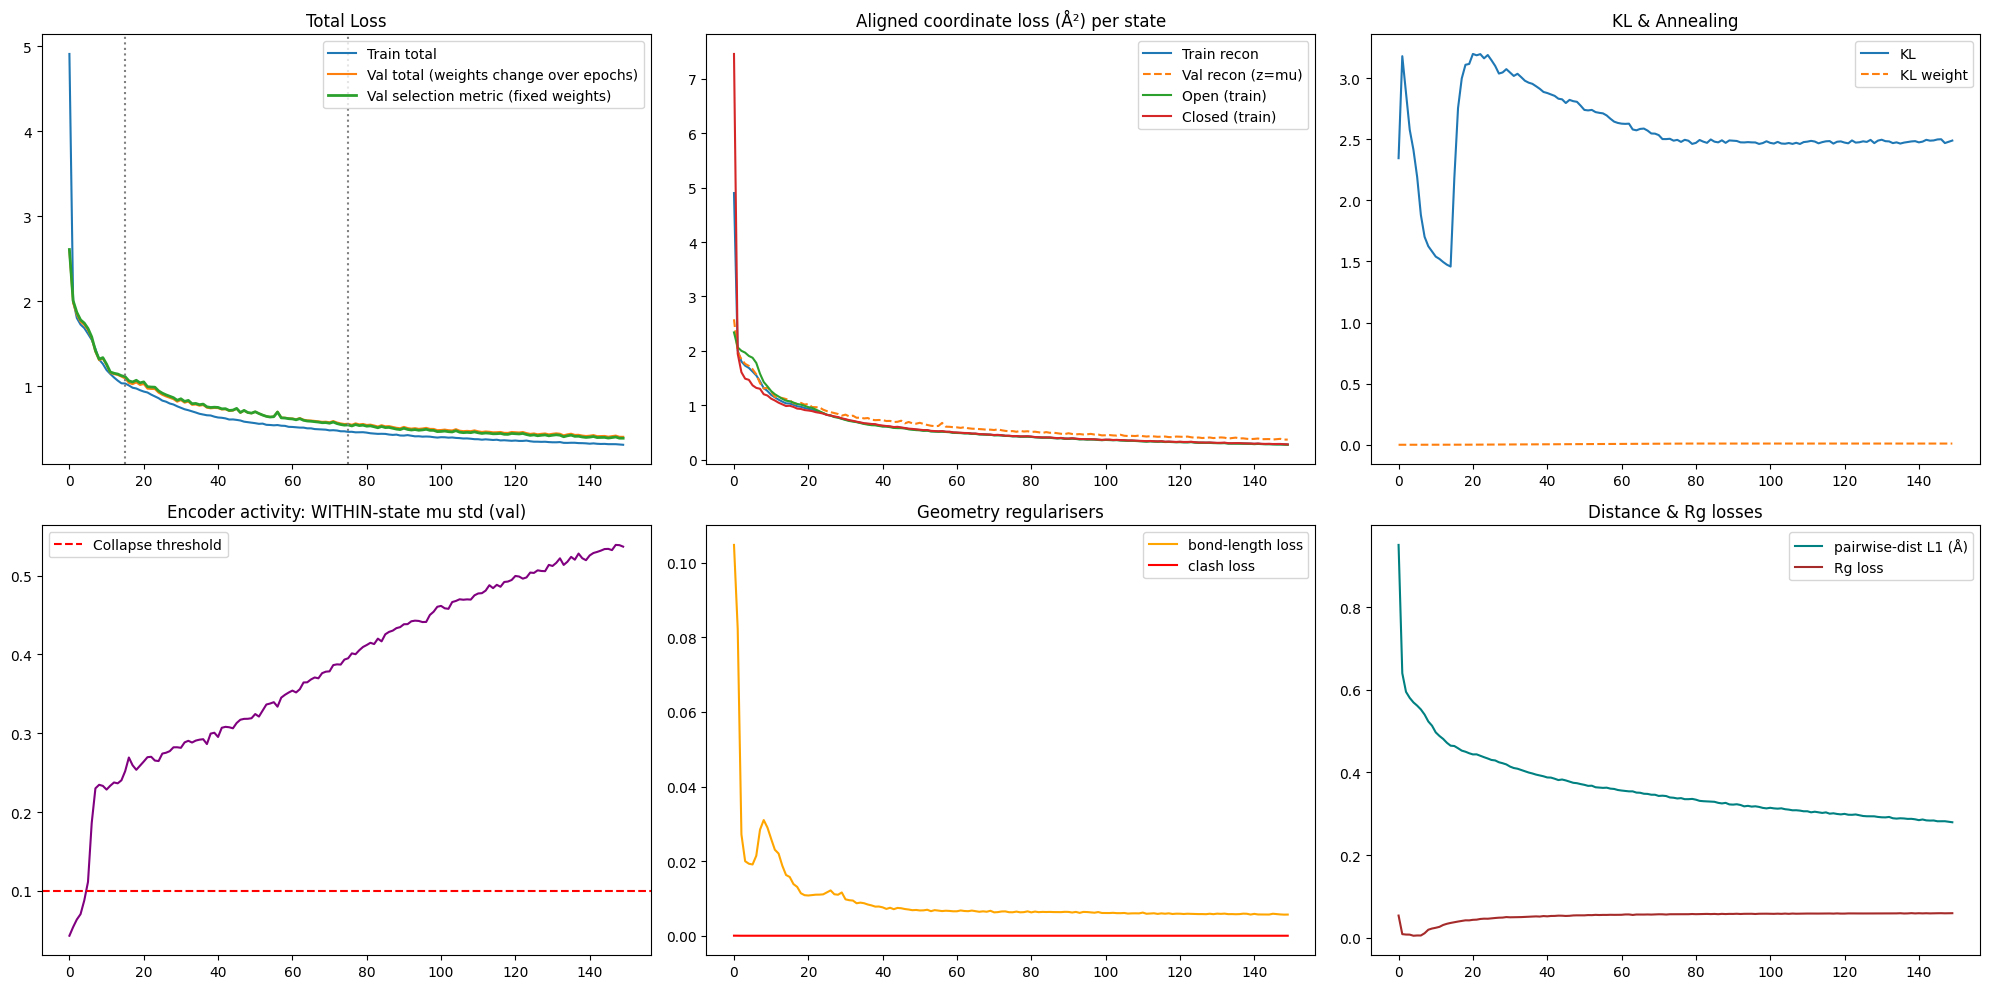

In [15]:
EPOCHS           = 150
LR               = 3e-4
AE_EPOCHS        = 15
KL_WARMUP        = 60
BETA_MAX         = 0.01
FREE_BITS        = 0.02
COLLAPSE_THR     = 0.1       # within-state mu std below this => decoder is effectively fed a constant
ES_PATIENCE      = 40        # counted only after the KL ramp is finished
ES_MIN_DELTA     = 1e-4
AUGMENT_SE3      = True      # feed the encoder randomly rotated + translated copies of each structure
FINAL_PHASE_START = AE_EPOCHS + KL_WARMUP

model     = ProteinSE3CVAE(template=global_ref, loc_stats=LOC_STATS).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=15, min_lr=1e-6
)

history = {k: [] for k in [
    'train_total', 'val_total', 'train_recon', 'val_recon', 'val_sel', 'train_kl', 'kl_weight',
    'recon_open', 'recon_closed', 'mu_within', 'lambda_dist', 'lambda_rg',
    'dist_raw', 'rg_raw', 'bond_raw', 'clash_raw',
]}

best_val_sel  = float('inf')
es_counter    = 0
stopped_epoch = None


def kl_beta_schedule(epoch: int) -> float:
    if epoch <= AE_EPOCHS:
        return 0.0
    return BETA_MAX * min(1.0, (epoch - AE_EPOCHS) / max(KL_WARMUP, 1))


def run_epoch(loader, train, epoch, kl_weight, lambda_dist, lambda_rg):
    model.train() if train else model.eval()
    keys = ['total', 'recon', 'kl', 'dist', 'rg', 'contact', 'bond', 'clash']
    agg  = {k: 0.0 for k in keys}
    agg.update({'recon_0': 0.0, 'recon_1': 0.0, 'n_0': 0, 'n_1': 0})
    mu_list, lab_list = [], []
    sampling = train and epoch > AE_EPOCHS          # validation is always deterministic (z = mu)
    ctx = torch.enable_grad() if train else torch.no_grad()

    with ctx:
        for x_batch, coords_batch, label_batch in loader:
            x_batch      = x_batch.to(DEVICE)
            coords_batch = coords_batch.to(DEVICE)
            label_batch  = label_batch.to(DEVICE)
            B = x_batch.shape[0]

            x_in = x_batch
            if train and AUGMENT_SE3:
                R    = random_rotation(B, DEVICE)
                x_in = torch.bmm(x_batch, R) + 20.0 * torch.randn(B, 1, 3, device=DEVICE)

            out = model(x_in, label_batch, sample=sampling)
            if not train:
                mu_list.append(out['mu'].detach().cpu()); lab_list.append(label_batch.cpu())

            losses = compute_total_loss(
                pred_coords=out['coords'], true_coords=coords_batch,
                mu=out['mu'], log_var=out['log_var'], labels_b=label_batch,
                kl_weight=kl_weight, free_bits=FREE_BITS,
                lambda_dist=lambda_dist, lambda_rg=lambda_rg,
            )

            if train:
                optimizer.zero_grad()
                losses['total'].backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()

            for k in keys:
                agg[k] += losses[k].item() * B
            with torch.no_grad():
                for s in [0, 1]:
                    mask = (label_batch == s)
                    if mask.any():
                        agg[f'recon_{s}'] += (aligned_coord_loss(out['coords'][mask], coords_batch[mask])
                                              / RECON_SCALE).item() * mask.sum().item()
                        agg[f'n_{s}'] += mask.sum().item()

    n = len(loader.dataset) if not train else len(loader) * loader.batch_size
    result = {k: agg[k] / n for k in keys}
    for s in [0, 1]:
        ns = agg[f'n_{s}']
        result[f'recon_{s}'] = agg[f'recon_{s}'] / ns if ns > 0 else 0.0
    if not train and mu_list:
        mu_all, lab_all = torch.cat(mu_list), torch.cat(lab_list)
        # FIX: collapse monitor = std of mu over frames WITHIN a state (the label alone already makes
        # mu differ between states, which fooled the old global mu_std)
        within = [mu_all[lab_all == s].std(0).mean().item() for s in (0, 1) if (lab_all == s).sum() > 1]
        result['mu_within'] = float(np.mean(within))
        result['mu_std']    = mu_all.std().item()
    else:
        result['mu_within'] = result['mu_std'] = None
    return result


print(f"{'Ep':>4} {'KL_w':>6} {'Tr':>8} {'Val':>8} {'Sel':>8} {'KL':>7} "
      f"{'mu_in':>7} {'bond':>7} {'clash':>7} {'Open':>8} {'Closed':>8}")
print('-' * 100)

for epoch in range(1, EPOCHS + 1):
    kl_w   = kl_beta_schedule(epoch)
    lam_d  = get_lambda_dist(epoch)
    lam_rg = get_lambda_rg(epoch)

    tr_losses  = run_epoch(train_loader, True,  epoch, kl_w, lam_d, lam_rg)
    val_losses = run_epoch(val_loader,   False, epoch, kl_w, lam_d, lam_rg)

    # FIX: fixed-weight, deterministic selection metric (the old val_total changed meaning every epoch
    # because lambda_dist / lambda_rg were being ramped)
    val_sel = val_losses['recon'] + BETA_MAX * val_losses['kl']
    final_phase = epoch > FINAL_PHASE_START
    if final_phase:
        scheduler.step(val_sel)
    mu_in = val_losses['mu_within']

    for key, v in [
        ('train_total', tr_losses['total']), ('val_total', val_losses['total']),
        ('train_recon', tr_losses['recon']), ('val_recon', val_losses['recon']), ('val_sel', val_sel),
        ('train_kl', tr_losses['kl']),       ('kl_weight', kl_w),
        ('recon_open', tr_losses['recon_0']), ('recon_closed', tr_losses['recon_1']),
        ('mu_within', mu_in), ('lambda_dist', lam_d), ('lambda_rg', lam_rg),
        ('dist_raw', tr_losses['dist']), ('rg_raw', tr_losses['rg']),
        ('bond_raw', tr_losses['bond']), ('clash_raw', tr_losses['clash']),
    ]:
        history[key].append(v)

    flag = ''
    if final_phase:
        if val_sel < best_val_sel - ES_MIN_DELTA:
            best_val_sel = val_sel
            es_counter   = 0
            torch.save(model.state_dict(), CKPT_PATH)
            flag = ' ★'
        else:
            es_counter += 1
            flag = f' ({es_counter}/{ES_PATIENCE})'

    if mu_in is not None and mu_in < COLLAPSE_THR and epoch > AE_EPOCHS + 5:
        print(f'  COLLAPSE WARNING epoch {epoch}: within-state mu std = {mu_in:.4f}')

    if epoch % 10 == 0 or epoch == 1:
        print(f'{epoch:4d} {kl_w:6.4f} {tr_losses["total"]:8.4f} {val_losses["total"]:8.4f} {val_sel:8.4f} '
              f'{tr_losses["kl"]:7.3f} {mu_in:7.3f} '
              f'{tr_losses["bond"]:7.4f} {tr_losses["clash"]:7.4f} '
              f'{tr_losses["recon_0"]:8.4f} {tr_losses["recon_1"]:8.4f}{flag}')

    if final_phase and es_counter >= ES_PATIENCE:
        stopped_epoch = epoch
        print(f'\n Early stopping at epoch {epoch}')
        break

if best_val_sel == float('inf'):          # never reached the final phase: keep the last weights
    torch.save(model.state_dict(), CKPT_PATH)
    print('WARNING: KL ramp never finished; saved last weights.')

if stopped_epoch is None:
    print(f'\nTraining complete ({EPOCHS} epochs). Best val_sel: {best_val_sel:.4f}')
else:
    print(f'Training complete (stopped epoch {stopped_epoch}). Best val_sel: {best_val_sel:.4f}')

model.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE))
print(f'Best checkpoint loaded from {CKPT_PATH}')

_fv = run_epoch(val_loader, False, EPOCHS, kl_beta_schedule(EPOCHS), get_lambda_dist(EPOCHS), get_lambda_rg(EPOCHS))
final_mu_std    = _fv['mu_std']
final_mu_within = _fv['mu_within']
print(f'\nEncoder  global mu_std={final_mu_std:.4f}   WITHIN-state mu_std={final_mu_within:.4f}')
print('Active' if final_mu_within > COLLAPSE_THR else 'COLLAPSED -- decoder still ignores z (see diagnostics cell)')

fig, axes = plt.subplots(2, 3, figsize=(20, 10))

axes[0,0].plot(history['train_total'], label='Train total')
axes[0,0].plot(history['val_total'],   label='Val total (weights change over epochs)')
axes[0,0].plot(history['val_sel'],     label='Val selection metric (fixed weights)', linewidth=2)
for ep_line, lab in [(AE_EPOCHS, 'AE→VAE'), (FINAL_PHASE_START, 'KL ramp done')]:
    axes[0,0].axvline(ep_line, color='grey', linestyle=':');
if stopped_epoch:
    axes[0,0].axvline(stopped_epoch - 1, color='red', linestyle=':', label='Early stop')
axes[0,0].set_title('Total Loss'); axes[0,0].legend()

axes[0,1].plot(history['train_recon'],  label='Train recon')
axes[0,1].plot(history['val_recon'],    label='Val recon (z=mu)', linestyle='--')
axes[0,1].plot(history['recon_open'],   label='Open (train)')
axes[0,1].plot(history['recon_closed'], label='Closed (train)')
axes[0,1].set_title('Aligned coordinate loss (Å²) per state'); axes[0,1].legend()

axes[0,2].plot(history['train_kl'],  label='KL')
axes[0,2].plot(history['kl_weight'], label='KL weight', linestyle='--')
axes[0,2].set_title('KL & Annealing'); axes[0,2].legend()

axes[1,0].plot(history['mu_within'], color='purple')
axes[1,0].axhline(COLLAPSE_THR, color='red', linestyle='--', label='Collapse threshold')
axes[1,0].set_title('Encoder activity: WITHIN-state mu std (val)'); axes[1,0].legend()

axes[1,1].plot(history['bond_raw'],  label='bond-length loss', color='orange')
axes[1,1].plot(history['clash_raw'], label='clash loss',       color='red')
axes[1,1].set_title('Geometry regularisers'); axes[1,1].legend()

axes[1,2].plot(history['dist_raw'], label='pairwise-dist L1 (Å)', color='teal')
axes[1,2].plot(history['rg_raw'],   label='Rg loss',              color='brown')
axes[1,2].set_title('Distance & Rg losses'); axes[1,2].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE}/training_curves_se3_v2.png', dpi=150)
plt.show()

### Generation and  Evaluation


In [16]:
N_GEN    = 500
GEN_TEMP = 1.0      # same temperature for every mode so the comparisons are fair


def _encode_train_state(s):
    sel = np.array([i for i in train_idx if labels[i] == s])
    xs  = torch.tensor(X[sel], dtype=torch.float32)
    ls  = torch.full((len(sel),), s, dtype=torch.long)
    mus, lvs = [], []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(sel), 64):
            mu, lv = model.encode(xs[i:i+64].to(DEVICE), ls[i:i+64].to(DEVICE))
            mus.append(mu.cpu()); lvs.append(lv.cpu())
    return torch.cat(mus), torch.cat(lvs)


print('Encoding TRAIN frames per state...')
ENC = {s: _encode_train_state(s) for s in (0, 1)}      # (mu, log_var) per state


def _aggregate_gaussian(s):
    """Per-state aggregate posterior: mean of mu, cov = Cov(mu) + E[sigma^2] (law of total variance, FULL covariance)."""
    mu, lv = ENC[s]
    mean = mu.mean(0)
    cov  = torch.cov(mu.T) + torch.diag(lv.exp().mean(0)) + 1e-5 * torch.eye(mu.shape[1])
    return mean, torch.linalg.cholesky(cov)


AGG = {s: _aggregate_gaussian(s) for s in (0, 1)}
for s in (0, 1):
    mu, lv = ENC[s]
    print(f'  State {s}: {len(mu)} train frames | mean-norm {AGG[s][0].norm():.3f} | '
          f'within-state mu std {mu.std(0).mean():.3f} | mean posterior std {lv.mul(0.5).exp().mean():.3f}')


def generate_state(state_label: int, n_samples: int, temperature: float = GEN_TEMP, mode: str = 'aggregate'):
    model.eval()
    if mode == 'prior':
        z = temperature * torch.randn(n_samples, LATENT_DIM)
    elif mode == 'aggregate':
        mean, L = AGG[state_label]
        z = mean + temperature * (torch.randn(n_samples, LATENT_DIM) @ L.T)
    elif mode == 'posterior':
        mu, lv = ENC[state_label]
        idx = torch.randint(0, len(mu), (n_samples,))
        z = mu[idx] + temperature * torch.exp(0.5 * lv[idx]) * torch.randn(n_samples, LATENT_DIM)
    else:
        raise ValueError(mode)

    z     = z.to(DEVICE)
    label = torch.full((n_samples,), state_label, dtype=torch.long, device=DEVICE)
    out = []
    with torch.no_grad():
        for i in range(0, n_samples, 64):
            out.append(model.decode(z[i:i+64], label[i:i+64]))
    coords = torch.cat(out)                                       # (n, N_CA, 3) in the template frame
    ref_t     = torch.tensor(global_ref, dtype=torch.float32, device=DEVICE)
    coords, _ = kabsch_align_torch(ref_t, coords)
    return coords.cpu()


def write_pdb_multimodel(coords_np, topology, output_path):
    if topology is None:
        raise ValueError('topology is None — cannot write PDB')
    traj = md.Trajectory(xyz=coords_np / 10.0, topology=topology)
    traj.save_pdb(output_path)
    print(f'  Saved {len(traj)} models → {output_path}')


print(f'\nGenerating {N_GEN} structures per state (T={GEN_TEMP})...')
gen_open        = generate_state(0, N_GEN, mode='aggregate')
gen_closed      = generate_state(1, N_GEN, mode='aggregate')
gen_open_prior  = generate_state(0, N_GEN, mode='prior')
gen_closed_prior= generate_state(1, N_GEN, mode='prior')
gen_open_post   = generate_state(0, N_GEN, mode='posterior')
gen_closed_post = generate_state(1, N_GEN, mode='posterior')
print(f'Generated open: {tuple(gen_open.shape)}   closed: {tuple(gen_closed.shape)}')

# diversity is judged against the DATA's own spread (the old fixed 1.0 Å threshold was above the data itself)
for name, s, gen in [('open / aggregate', 0, gen_open), ('closed / aggregate', 1, gen_closed),
                     ('open / prior', 0, gen_open_prior), ('closed / prior', 1, gen_closed_prior),
                     ('open / posterior', 0, gen_open_post), ('closed / posterior', 1, gen_closed_post)]:
    data_std = coords_train[labels_train == s].std(0).mean()
    gstd = gen.std(0).mean().item()
    ratio = gstd / data_std
    flag = '  ✓' if 0.7 <= ratio <= 1.3 else ('  ⚠ too narrow' if ratio < 0.7 else '  ⚠ too broad')
    print(f'  Diversity ({name:20s}): gen std {gstd:.3f} Å  vs data {data_std:.3f} Å  (ratio {ratio:.2f}){flag}')

write_pdb_multimodel(gen_open.numpy(),   ca_topology, f'{DRIVE}/generated_open_aggregate.pdb')
write_pdb_multimodel(gen_closed.numpy(), ca_topology, f'{DRIVE}/generated_closed_aggregate.pdb')
write_pdb_multimodel(gen_open_prior.numpy(),   ca_topology, f'{DRIVE}/generated_open_prior.pdb')
write_pdb_multimodel(gen_closed_prior.numpy(), ca_topology, f'{DRIVE}/generated_closed_prior.pdb')

Encoding TRAIN frames per state...
  State 0: 1391 train frames | mean-norm 1.709 | within-state mu std 0.559 | mean posterior std 0.064
  State 1: 1393 train frames | mean-norm 0.912 | within-state mu std 0.522 | mean posterior std 0.057

Generating 500 structures per state (T=1.0)...
Generated open: (500, 162, 3)   closed: (500, 162, 3)
  Diversity (open / aggregate    ): gen std 0.519 Å  vs data 0.589 Å  (ratio 0.88)  ✓
  Diversity (closed / aggregate  ): gen std 0.477 Å  vs data 0.569 Å  (ratio 0.84)  ✓
  Diversity (open / prior        ): gen std 0.434 Å  vs data 0.589 Å  (ratio 0.74)  ✓
  Diversity (closed / prior      ): gen std 0.490 Å  vs data 0.569 Å  (ratio 0.86)  ✓
  Diversity (open / posterior    ): gen std 0.523 Å  vs data 0.589 Å  (ratio 0.89)  ✓
  Diversity (closed / posterior  ): gen std 0.493 Å  vs data 0.569 Å  (ratio 0.87)  ✓
  Saved 500 models → /content/drive/MyDrive/generated_open_aggregate.pdb
  Saved 500 models → /content/drive/MyDrive/generated_closed_aggregate

### RMSD and  Dihedral Plots

Test set: open=300  closed=300
Computing RMSD (gen -> nearest test) and coverage (test -> nearest gen)...


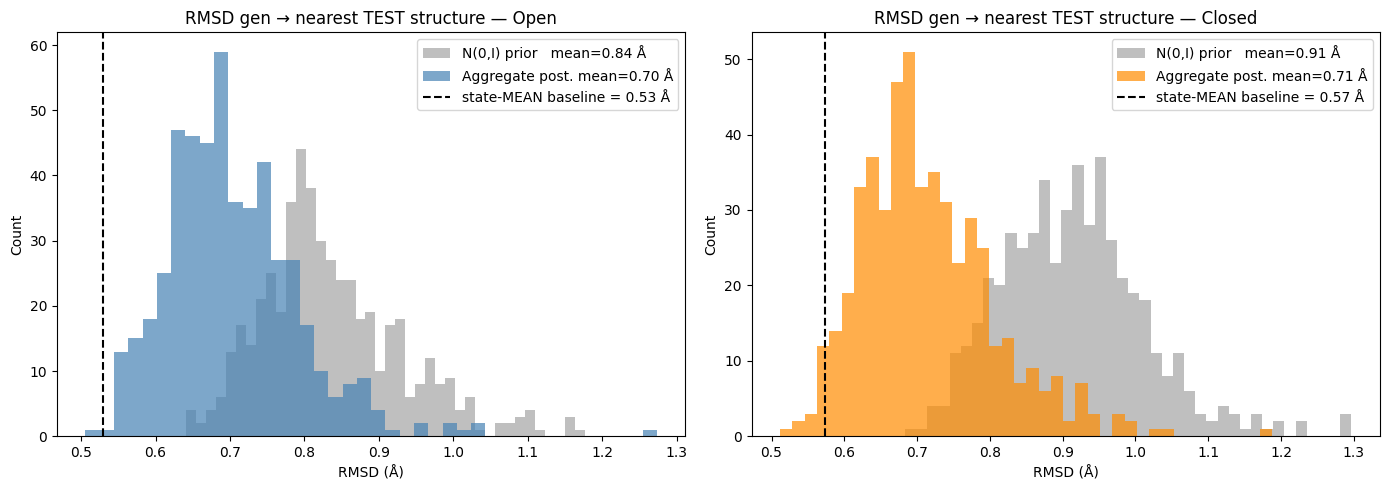


Cα Pseudo-Dihedral Plot (NOT Ramachandran)...


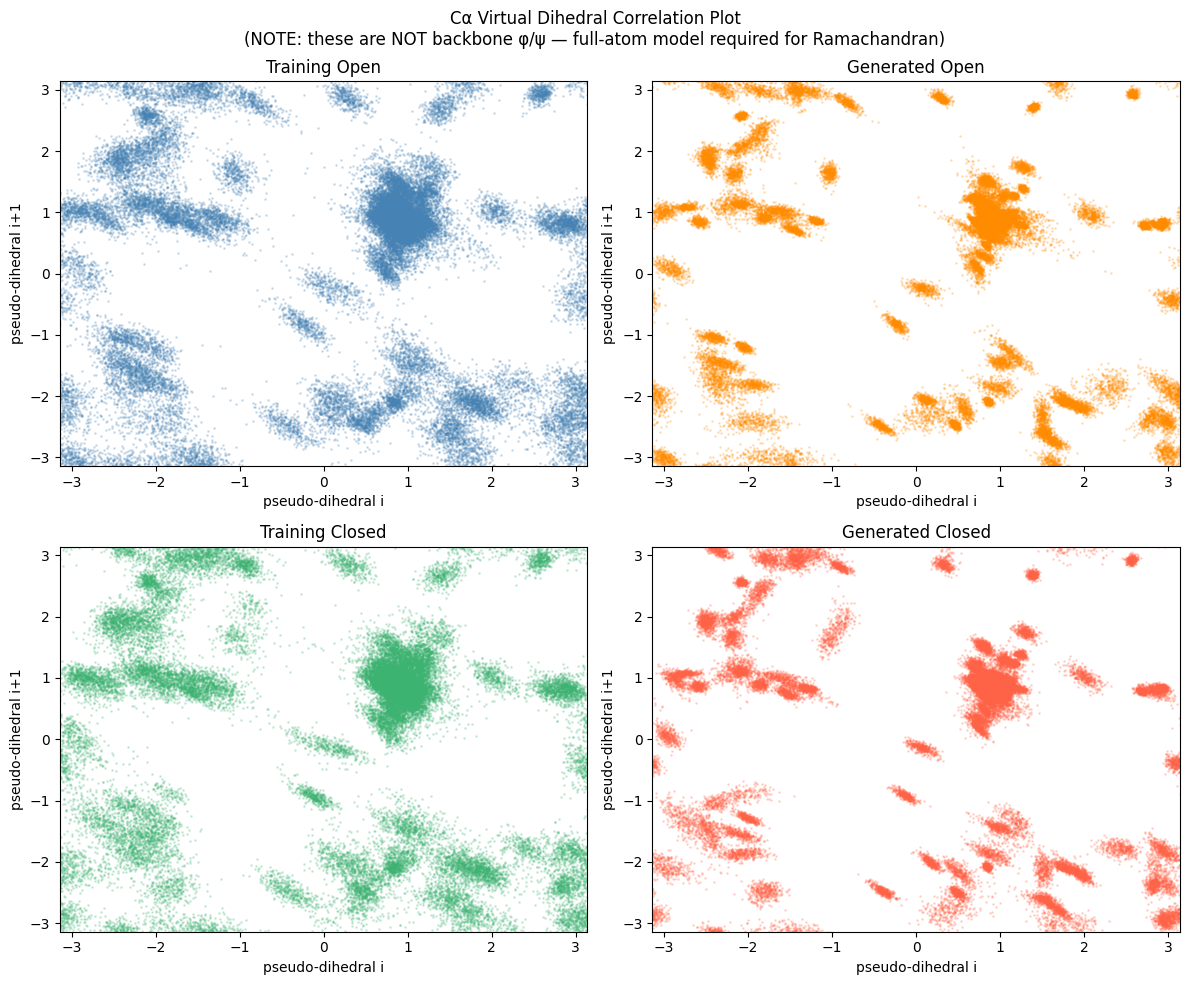


Radius of Gyration...
  Open   — test: 17.03±0.28  gen: 17.00±0.27 Å  (NB: Rg is trained on, so this is not an independent check)
  Closed — test: 16.43±0.19  gen: 16.39±0.19 Å  (NB: Rg is trained on, so this is not an independent check)


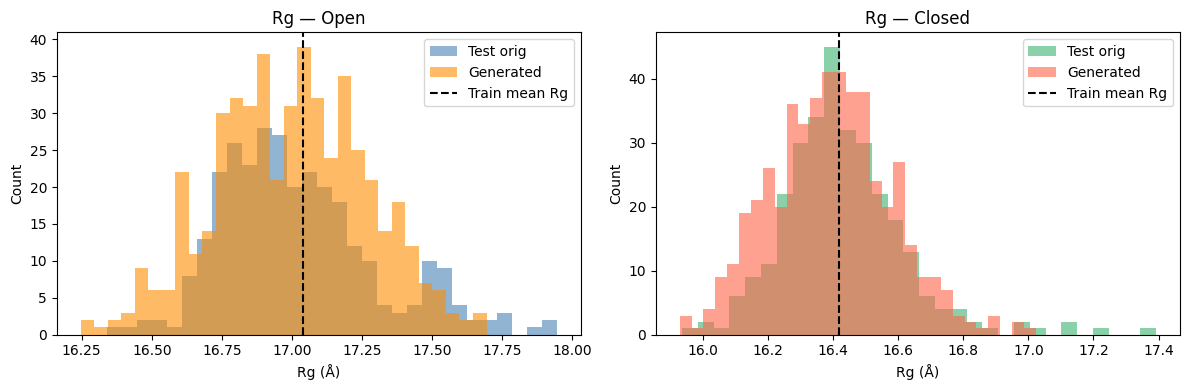


Contact maps vs TEST set (and train-frames-vs-test reference)...
    contact gen open  : N_gen=500  N_orig=300  F1=0.9900  prob-MAE=0.0015
    contact gen closed: N_gen=500  N_orig=300  F1=0.9868  prob-MAE=0.0016
    contact train open : N_gen=1391  N_orig=300  F1=1.0000  prob-MAE=0.0003
    contact train closed: N_gen=1393  N_orig=300  F1=0.9900  prob-MAE=0.0004


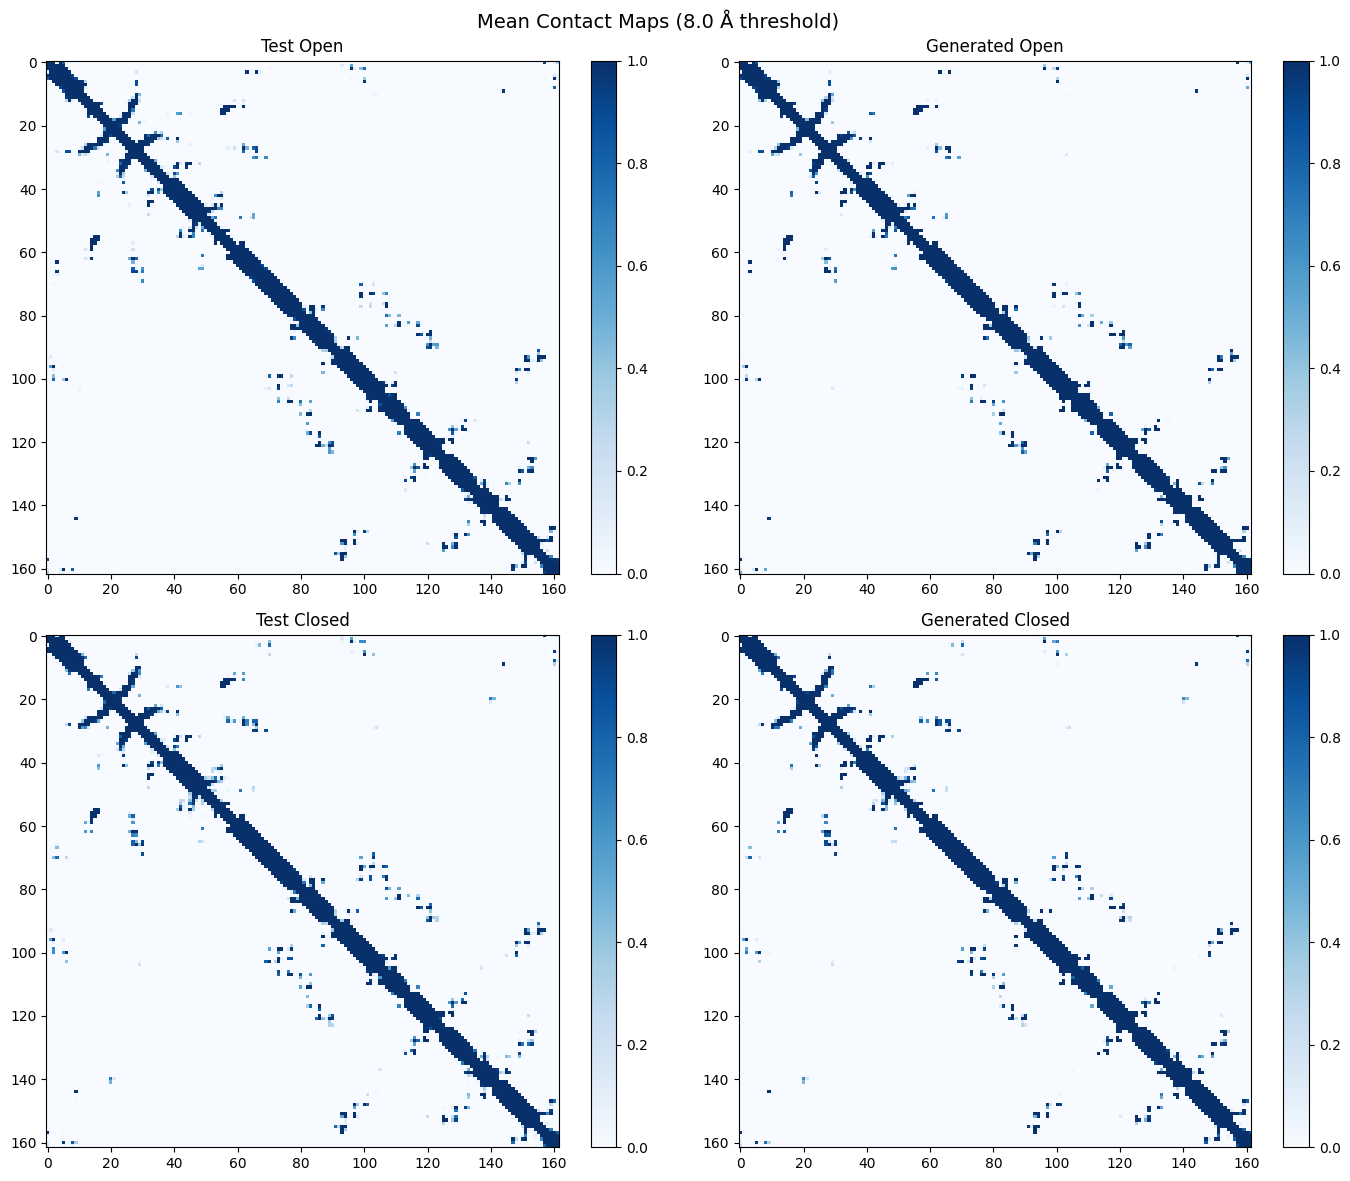


Structure overlays...


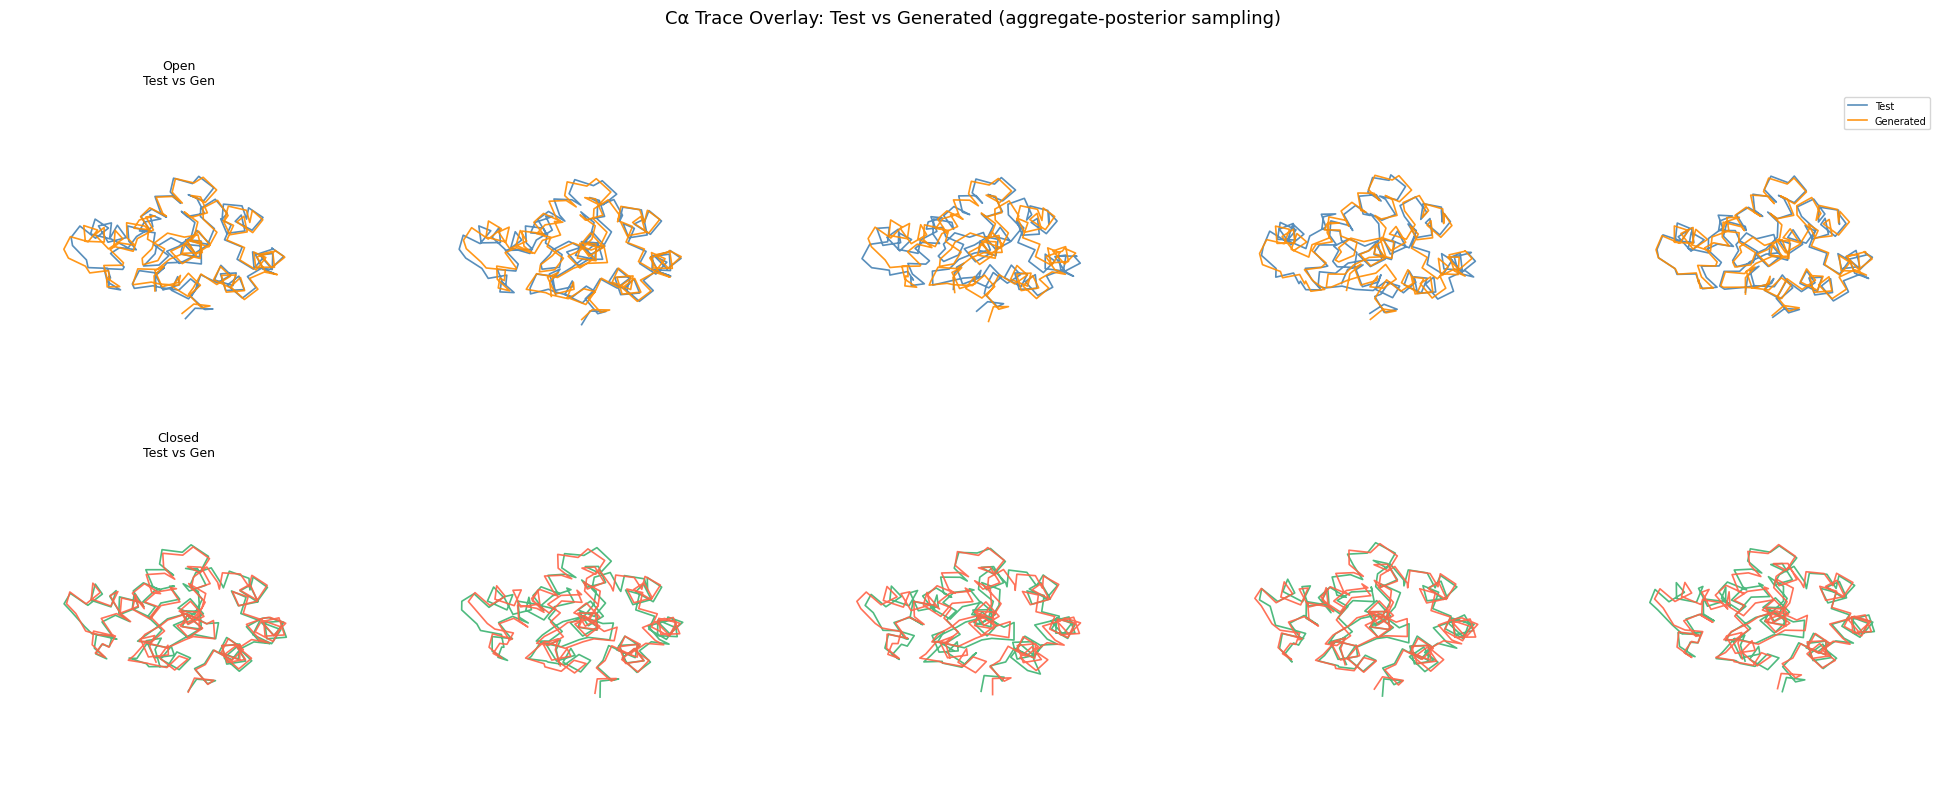


EVALUATION SUMMARY  (metrics vs held-out TEST set; baselines in brackets)
Metric                                                 Open       Closed
------------------------------------------------------------------------------
RMSD gen->test, aggregate (Å)                          0.70         0.71
RMSD gen->test, N(0,I) prior (Å)                       0.84         0.91
  [baseline] state-mean structure (Å)                  0.53         0.57
  [baseline] real train frames (Å)                     0.80         0.79
Coverage test->gen (Å, lower=better)                   0.70         0.71
  [reference] test->nearest train frame (Å)            0.75         0.72
  [collapsed] test->state mean (Å)                     1.06         0.98
Rg mean generated (Å)                                 17.00        16.39
Rg mean test (Å)                                      17.03        16.43
Rg std generated / test (Å)                     0.27/0.28   0.19/0.19 
Contact F1 (|i-j|>=4)                        

In [17]:
def compute_rmsd_to_nearest(gen: np.ndarray, orig: np.ndarray) -> np.ndarray:
    """For each structure in `gen`: RMSD (Å) to the nearest structure in `orig` (all in the global_ref frame)."""
    rmsds = []
    for g in gen:
        r = np.sqrt(((orig - g[None]) ** 2).sum(-1).mean(-1))
        rmsds.append(r.min())
    return np.array(rmsds)


def radius_of_gyration(coords: np.ndarray) -> np.ndarray:
    centres = coords.mean(axis=1, keepdims=True)
    return np.sqrt(((coords - centres) ** 2).sum(-1).mean(-1))


_TRIU = np.triu(np.ones((N_CA, N_CA), dtype=bool), k=4)

def mean_contact_prob(ca, threshold=CONTACT_THR, chunk=100):
    acc = np.zeros((N_CA, N_CA))
    for i in range(0, len(ca), chunk):
        c = ca[i:i + chunk]
        d = np.linalg.norm(c[:, :, None] - c[:, None, :], axis=-1)
        acc += (d < threshold).sum(0)
    return acc / len(ca)


def contact_scores(gen, orig, tag=''):
    """F1 of the thresholded mean contact maps AND the mean abs. error of the continuous contact probabilities."""
    pg, po = mean_contact_prob(gen), mean_contact_prob(orig)
    f1  = f1_score((po > 0.5)[_TRIU].astype(int), (pg > 0.5)[_TRIU].astype(int), zero_division=0)
    mae = np.abs(pg - po)[_TRIU].mean()
    print(f'    contact {tag}: N_gen={len(gen)}  N_orig={len(orig)}  F1={f1:.4f}  prob-MAE={mae:.4f}')
    return f1, mae


def ca_pseudo_dihedrals(ca: np.ndarray) -> np.ndarray:
    """Cα virtual dihedrals (NOT backbone φ/ψ). Returns (F, N-3)."""
    b1 = ca[:, 1:-2] - ca[:, :-3]
    b2 = ca[:, 2:-1] - ca[:, 1:-2]
    b3 = ca[:, 3:]   - ca[:, 2:-1]
    n1 = np.cross(b1, b2); n1 /= (np.linalg.norm(n1, axis=-1, keepdims=True) + EPS)
    n2 = np.cross(b2, b3); n2 /= (np.linalg.norm(n2, axis=-1, keepdims=True) + EPS)
    b2u = b2 / (np.linalg.norm(b2, axis=-1, keepdims=True) + EPS)
    return np.arctan2((np.cross(n1, n2) * b2u).sum(-1), (n1 * n2).sum(-1))


orig_open   = coords_test[labels_test == 0]
orig_closed = coords_test[labels_test == 1]
train_open   = coords_train[labels_train == 0]
train_closed = coords_train[labels_train == 1]
gen_open_np   = gen_open.numpy();   gen_closed_np   = gen_closed.numpy()
gen_open_pr   = gen_open_prior.numpy(); gen_closed_pr = gen_closed_prior.numpy()

print(f'Test set: open={len(orig_open)}  closed={len(orig_closed)}')

# ───── RMSD, with BASELINES (a collapsed model that outputs the state mean must NOT look good) ─────
print('Computing RMSD (gen -> nearest test) and coverage (test -> nearest gen)...')
rmsd_open_agg    = compute_rmsd_to_nearest(gen_open_np,   orig_open)
rmsd_closed_agg  = compute_rmsd_to_nearest(gen_closed_np, orig_closed)
rmsd_open_prior  = compute_rmsd_to_nearest(gen_open_pr,   orig_open)
rmsd_closed_prior= compute_rmsd_to_nearest(gen_closed_pr, orig_closed)

rng = np.random.default_rng(0)
mean_open, mean_closed = train_open.mean(0), train_closed.mean(0)
base_mean_open   = compute_rmsd_to_nearest(mean_open[None],   orig_open)[0]
base_mean_closed = compute_rmsd_to_nearest(mean_closed[None], orig_closed)[0]
base_tr_open     = compute_rmsd_to_nearest(train_open[rng.choice(len(train_open), 300, replace=False)],     orig_open).mean()
base_tr_closed   = compute_rmsd_to_nearest(train_closed[rng.choice(len(train_closed), 300, replace=False)], orig_closed).mean()

cov_open   = compute_rmsd_to_nearest(orig_open,   gen_open_np).mean()       # test -> gen (coverage)
cov_closed = compute_rmsd_to_nearest(orig_closed, gen_closed_np).mean()
cov_open_train   = compute_rmsd_to_nearest(orig_open,   train_open).mean()  # reference: real train frames
cov_closed_train = compute_rmsd_to_nearest(orig_closed, train_closed).mean()
cov_open_mean   = np.sqrt(((orig_open   - mean_open[None])   ** 2).sum(-1).mean(-1)).mean()   # collapsed-model reference
cov_closed_mean = np.sqrt(((orig_closed - mean_closed[None]) ** 2).sum(-1).mean(-1)).mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (r_agg, r_prior, base, title) in zip(axes, [
    (rmsd_open_agg,   rmsd_open_prior,   base_mean_open,   'Open'),
    (rmsd_closed_agg, rmsd_closed_prior, base_mean_closed, 'Closed'),
]):
    ax.hist(r_prior, bins=40, alpha=0.5, color='grey', label=f'N(0,I) prior   mean={r_prior.mean():.2f} Å')
    ax.hist(r_agg,   bins=40, alpha=0.7, color='steelblue' if title == 'Open' else 'darkorange',
            label=f'Aggregate post. mean={r_agg.mean():.2f} Å')
    ax.axvline(base, linestyle='--', color='black', label=f'state-MEAN baseline = {base:.2f} Å')
    ax.set_title(f'RMSD gen → nearest TEST structure — {title}')
    ax.set_xlabel('RMSD (Å)'); ax.set_ylabel('Count'); ax.legend()
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_rmsd_se3_v2.png', dpi=150)
plt.show()

print('\nCα Pseudo-Dihedral Plot (NOT Ramachandran)...')
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
pairs = [
    (train_open,    'Training Open',     'steelblue'),
    (gen_open_np,   'Generated Open',    'darkorange'),
    (train_closed,  'Training Closed',   'mediumseagreen'),
    (gen_closed_np, 'Generated Closed',  'tomato'),
]
for ax, (ca, title, col) in zip(axes.flat, pairs):
    d   = ca_pseudo_dihedrals(ca)                       # (F, N-3)
    phi = d[:, :-1].ravel(); psi = d[:, 1:].ravel()     # FIX: pair (i, i+1) WITHIN each frame
    sub_i = np.random.default_rng(0).choice(len(phi), min(len(phi), 60000), replace=False)
    ax.scatter(phi[sub_i], psi[sub_i], s=1, alpha=0.2, color=col)
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xlabel('pseudo-dihedral i'); ax.set_ylabel('pseudo-dihedral i+1')
    ax.set_title(title)
plt.suptitle('Cα Virtual Dihedral Correlation Plot\n'
             '(NOTE: these are NOT backbone φ/ψ — full-atom model required for Ramachandran)', fontsize=12)
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_ca_dihedrals_se3_v2.png', dpi=150)
plt.show()

print('\nRadius of Gyration...')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (gen, orig, title, co, cg) in zip(axes, [
    (gen_open_np,   orig_open,   'Open',   'steelblue',      'darkorange'),
    (gen_closed_np, orig_closed, 'Closed', 'mediumseagreen', 'tomato'),
]):
    rg_o = radius_of_gyration(orig)
    rg_g = radius_of_gyration(gen)
    ax.hist(rg_o, bins=30, alpha=0.6, label='Test orig',  color=co)
    ax.hist(rg_g, bins=30, alpha=0.6, label='Generated',  color=cg)
    ax.axvline(RG_TARGET[0 if title == 'Open' else 1].item(), color='black', linestyle='--', label='Train mean Rg')
    ax.set_title(f'Rg — {title}')
    ax.set_xlabel('Rg (Å)'); ax.set_ylabel('Count'); ax.legend()
    print(f'  {title:6s} — test: {rg_o.mean():.2f}±{rg_o.std():.2f}  gen: {rg_g.mean():.2f}±{rg_g.std():.2f} Å  '
          f'(NB: Rg is trained on, so this is not an independent check)')
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_rg_se3_v2.png', dpi=150)
plt.show()
rg_open_gen   = radius_of_gyration(gen_open_np)
rg_closed_gen = radius_of_gyration(gen_closed_np)

print('\nContact maps vs TEST set (and train-frames-vs-test reference)...')
f1_open,   mae_open   = contact_scores(gen_open_np,   orig_open,   tag='gen open  ')
f1_closed, mae_closed = contact_scores(gen_closed_np, orig_closed, tag='gen closed')
f1_open_tr,   mae_open_tr   = contact_scores(train_open,   orig_open,   tag='train open ')
f1_closed_tr, mae_closed_tr = contact_scores(train_closed, orig_closed, tag='train closed')

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
titles = ['Test Open', 'Generated Open', 'Test Closed', 'Generated Closed']
arrs   = [orig_open[:100], gen_open_np[:100], orig_closed[:100], gen_closed_np[:100]]
for ax, title, ca_arr in zip(axes.flat, titles, arrs):
    im = ax.imshow(mean_contact_prob(ca_arr), cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle(f'Mean Contact Maps ({CONTACT_THR} Å threshold)', fontsize=14)
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_contact_maps_se3_v2.png', dpi=150)
plt.show()

print('\nStructure overlays...')
fig = plt.figure(figsize=(20, 8))
for row, (orig, gen, state_name, col_o, col_g) in enumerate([
    (orig_open,   gen_open_np,   'Open',   'steelblue',     'darkorange'),
    (orig_closed, gen_closed_np, 'Closed', 'mediumseagreen', 'tomato'),
]):
    o_idx = np.random.choice(len(orig), min(5, len(orig)), replace=False)
    g_idx = np.random.choice(len(gen),  5, replace=False)
    for col, (io, ig) in enumerate(zip(o_idx, g_idx)):
        ax = fig.add_subplot(2, 5, row * 5 + col + 1, projection='3d')
        o  = orig[io]; g = gen[ig]
        ax.plot(o[:, 0], o[:, 1], o[:, 2], color=col_o, lw=1.2, alpha=0.9, label='Test')
        ax.plot(g[:, 0], g[:, 1], g[:, 2], color=col_g, lw=1.2, alpha=0.9, label='Generated')
        ax.set_axis_off()
        if col == 0: ax.set_title(f'{state_name}\nTest vs Gen', fontsize=9)
        if row == 0 and col == 4: ax.legend(fontsize=7, loc='upper right')
plt.suptitle('Cα Trace Overlay: Test vs Generated (aggregate-posterior sampling)', fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_overlay_se3_v2.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n' + '=' * 78)
print('EVALUATION SUMMARY  (metrics vs held-out TEST set; baselines in brackets)')
print('=' * 78)
print(f'{"Metric":<46} {"Open":>12} {"Closed":>12}')
print('-' * 78)
print(f'{"RMSD gen->test, aggregate (Å)":<46} {rmsd_open_agg.mean():>12.2f} {rmsd_closed_agg.mean():>12.2f}')
print(f'{"RMSD gen->test, N(0,I) prior (Å)":<46} {rmsd_open_prior.mean():>12.2f} {rmsd_closed_prior.mean():>12.2f}')
print(f'{"  [baseline] state-mean structure (Å)":<46} {base_mean_open:>12.2f} {base_mean_closed:>12.2f}')
print(f'{"  [baseline] real train frames (Å)":<46} {base_tr_open:>12.2f} {base_tr_closed:>12.2f}')
print(f'{"Coverage test->gen (Å, lower=better)":<46} {cov_open:>12.2f} {cov_closed:>12.2f}')
print(f'{"  [reference] test->nearest train frame (Å)":<46} {cov_open_train:>12.2f} {cov_closed_train:>12.2f}')
print(f'{"  [collapsed] test->state mean (Å)":<46} {cov_open_mean:>12.2f} {cov_closed_mean:>12.2f}')
print(f'{"Rg mean generated (Å)":<46} {rg_open_gen.mean():>12.2f} {rg_closed_gen.mean():>12.2f}')
print(f'{"Rg mean test (Å)":<46} {radius_of_gyration(orig_open).mean():>12.2f} {radius_of_gyration(orig_closed).mean():>12.2f}')
print(f'{"Rg std generated / test (Å)":<46} {rg_open_gen.std():>5.2f}/{radius_of_gyration(orig_open).std():<5.2f} {rg_closed_gen.std():>5.2f}/{radius_of_gyration(orig_closed).std():<5.2f}')
print(f'{"Contact F1 (|i-j|>=4)":<46} {f1_open:>12.4f} {f1_closed:>12.4f}')
print(f'{"Contact prob MAE (lower=better)":<46} {mae_open:>12.4f} {mae_closed:>12.4f}')
print(f'{"  [baseline] train frames vs test, MAE":<46} {mae_open_tr:>12.4f} {mae_closed_tr:>12.4f}')
print(f'{"Encoder within-state mu std":<46} {final_mu_within:>12.4f} {"(shared)":>12}')
stop_info = f'epoch {stopped_epoch}' if stopped_epoch else f'{EPOCHS} epochs'
print(f'{"Training stopped at":<46} {stop_info:>25}')
print('=' * 78)
print('Reading guide: coverage close to the [collapsed] row = the model is just producing the state mean.')
print('\n All evaluation figures saved to Drive.')

### Internal Coordinate Distributions


Internal Coordinate Distributions...


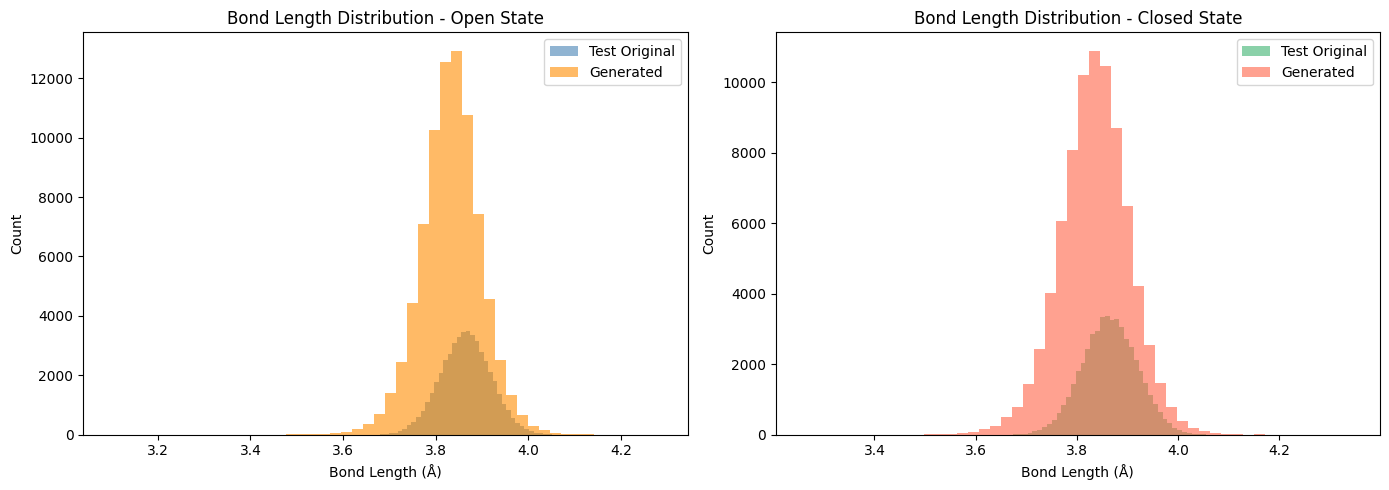


Cα–Cα bond statistics (target 3.8 Å, tolerance ±0.3 Å):
  test open    mean 3.865  std 0.055  outside tol: 0.00%
  gen open     mean 3.834  std 0.065  outside tol: 0.10%
  test closed  mean 3.865  std 0.055  outside tol: 0.00%
  gen closed   mean 3.835  std 0.069  outside tol: 0.07%


In [18]:
print('\nInternal Coordinate Distributions...')

# Bond Length Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Open State Bonds
bonds_open_orig = np.array([compute_bonds(f) for f in orig_open]).ravel()
bonds_open_gen = np.array([compute_bonds(f) for f in gen_open_np]).ravel()
axes[0].hist(bonds_open_orig, bins=50, alpha=0.6, label='Test Original', color='steelblue')
axes[0].hist(bonds_open_gen, bins=50, alpha=0.6, label='Generated', color='darkorange')
axes[0].set_title('Bond Length Distribution - Open State')
axes[0].set_xlabel('Bond Length (Å)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Closed State Bonds
bonds_closed_orig = np.array([compute_bonds(f) for f in orig_closed]).ravel()
bonds_closed_gen = np.array([compute_bonds(f) for f in gen_closed_np]).ravel()
axes[1].hist(bonds_closed_orig, bins=50, alpha=0.6, label='Test Original', color='mediumseagreen')
axes[1].hist(bonds_closed_gen, bins=50, alpha=0.6, label='Generated', color='tomato')
axes[1].set_title('Bond Length Distribution - Closed State')
axes[1].set_xlabel('Bond Length (Å)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_bond_distributions_se3_v2.png', dpi=150)
plt.show()

# FIX: quantify chain geometry instead of only eyeballing the histograms
print('\nCα–Cα bond statistics (target %.1f Å, tolerance ±%.1f Å):' % (CA_BOND_A, CA_BOND_TOL))
for name, b in [('test open', bonds_open_orig), ('gen open', bonds_open_gen),
                ('test closed', bonds_closed_orig), ('gen closed', bonds_closed_gen)]:
    print(f'  {name:12s} mean {b.mean():.3f}  std {b.std():.3f}  outside tol: {100 * (np.abs(b - CA_BOND_A) > CA_BOND_TOL).mean():.2f}%')

### Bond Angle Distributions

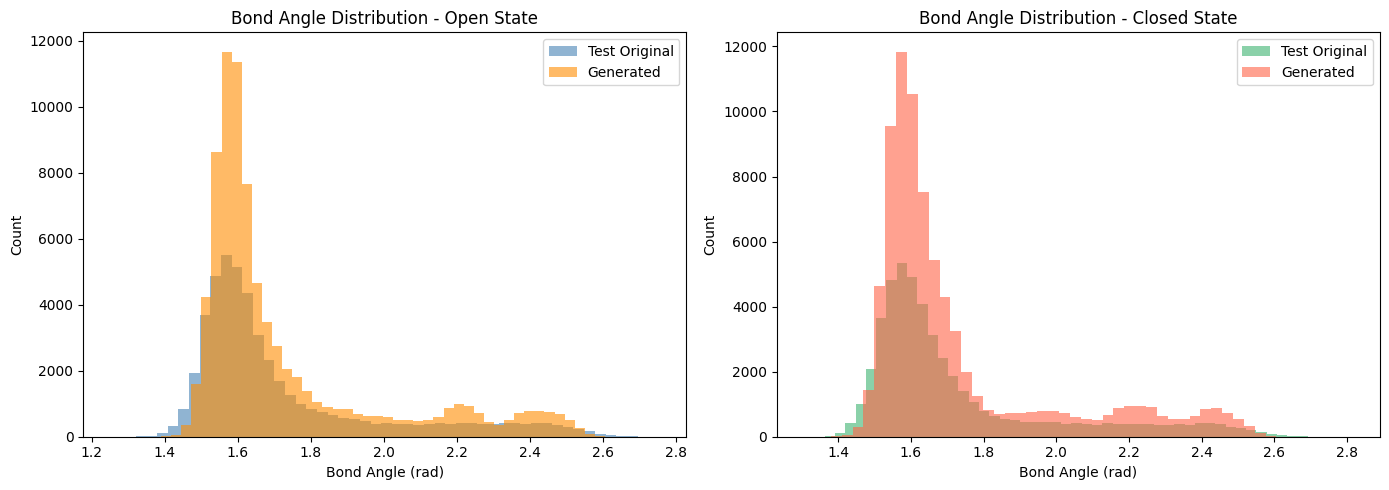

In [19]:
# Bond Angle Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Open State Angles
angles_open_orig = np.array([compute_angles(f) for f in orig_open]).ravel()
angles_open_gen = np.array([compute_angles(f) for f in gen_open_np]).ravel()
axes[0].hist(angles_open_orig, bins=50, alpha=0.6, label='Test Original', color='steelblue')
axes[0].hist(angles_open_gen, bins=50, alpha=0.6, label='Generated', color='darkorange')
axes[0].set_title('Bond Angle Distribution - Open State')
axes[0].set_xlabel('Bond Angle (rad)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Closed State Angles
angles_closed_orig = np.array([compute_angles(f) for f in orig_closed]).ravel()
angles_closed_gen = np.array([compute_angles(f) for f in gen_closed_np]).ravel()
axes[1].hist(angles_closed_orig, bins=50, alpha=0.6, label='Test Original', color='mediumseagreen')
axes[1].hist(angles_closed_gen, bins=50, alpha=0.6, label='Generated', color='tomato')
axes[1].set_title('Bond Angle Distribution - Closed State')
axes[1].set_xlabel('Bond Angle (rad)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_angle_distributions_se3_v2.png', dpi=150)
plt.show()

### Dihedral Distributions

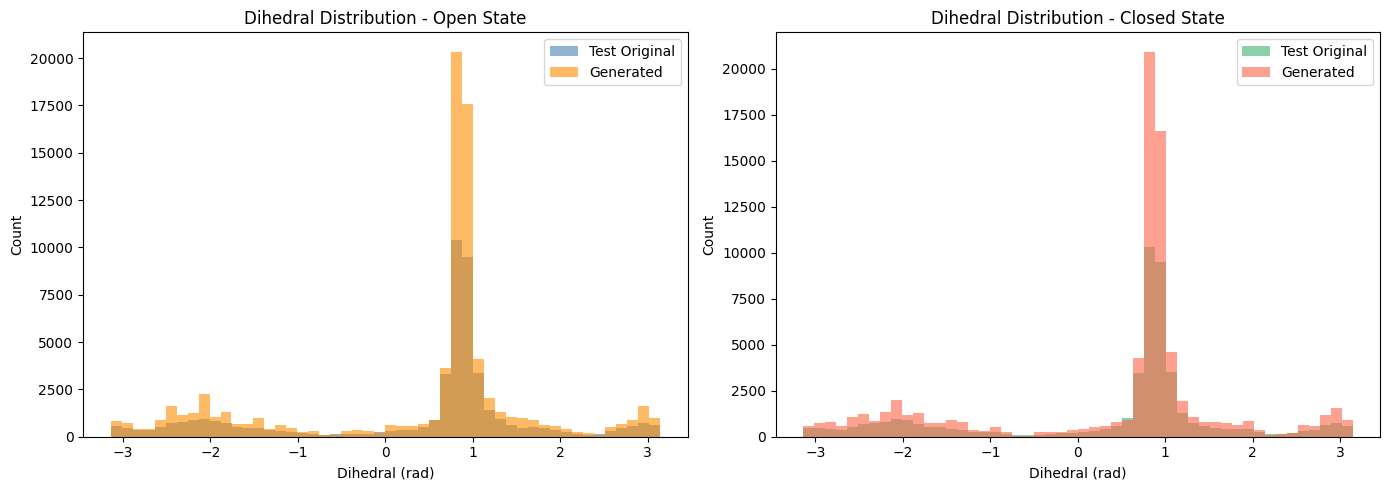

In [20]:
# Dihedral Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Open State Dihedrals
dihedrals_open_orig = compute_dihedrals_batch(orig_open).ravel()
dihedrals_open_gen = compute_dihedrals_batch(gen_open_np).ravel()
axes[0].hist(dihedrals_open_orig, bins=50, alpha=0.6, label='Test Original', color='steelblue')
axes[0].hist(dihedrals_open_gen, bins=50, alpha=0.6, label='Generated', color='darkorange')
axes[0].set_title('Dihedral Distribution - Open State')
axes[0].set_xlabel('Dihedral (rad)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Closed State Dihedrals
dihedrals_closed_orig = compute_dihedrals_batch(orig_closed).ravel()
dihedrals_closed_gen = compute_dihedrals_batch(gen_closed_np).ravel()
axes[1].hist(dihedrals_closed_orig, bins=50, alpha=0.6, label='Test Original', color='mediumseagreen')
axes[1].hist(dihedrals_closed_gen, bins=50, alpha=0.6, label='Generated', color='tomato')
axes[1].set_title('Dihedral Distribution - Closed State')
axes[1].set_xlabel('Dihedral (rad)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_dihedral_distributions_se3_v2.png', dpi=150)
plt.show()

### Latent diagnostics (per state)


State 0: active units (Var_x[mu]>0.01) = 64/64   |   KL>0.01 dims = 64/64   |   total KL = 157.36 nats
State 1: active units (Var_x[mu]>0.01) = 64/64   |   KL>0.01 dims = 64/64   |   total KL = 162.14 nats


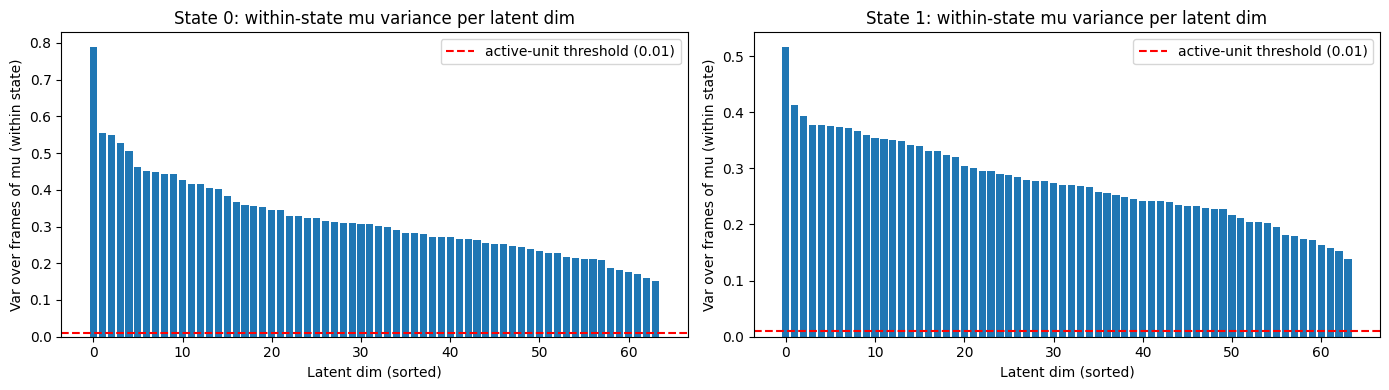

In [21]:
def latent_diagnostics(thr_au=0.01, thr_kl=0.01):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for s, ax in zip((0, 1), axes):
        mu, lv = ENC[s]                                           # TRAIN frames of this state
        kl_per_dim = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).mean(0)
        var_mu     = mu.var(0)
        n_au = (var_mu > thr_au).sum().item()
        n_kl = (kl_per_dim > thr_kl).sum().item()
        print(f'State {s}: active units (Var_x[mu]>{thr_au}) = {n_au}/{mu.shape[1]}   |   KL>{thr_kl} dims = {n_kl}/{mu.shape[1]}   '
              f'|   total KL = {kl_per_dim.sum():.2f} nats')
        order = torch.argsort(var_mu, descending=True)
        ax.bar(range(len(var_mu)), var_mu[order].numpy())
        ax.axhline(thr_au, color='r', linestyle='--', label=f'active-unit threshold ({thr_au})')
        ax.set_xlabel('Latent dim (sorted)'); ax.set_ylabel('Var over frames of mu (within state)')
        ax.set_title(f'State {s}: within-state mu variance per latent dim'); ax.legend()
    plt.tight_layout()
    plt.savefig(f'{DRIVE}/diag_latent_activity.png', dpi=150)
    plt.show()

latent_diagnostics()

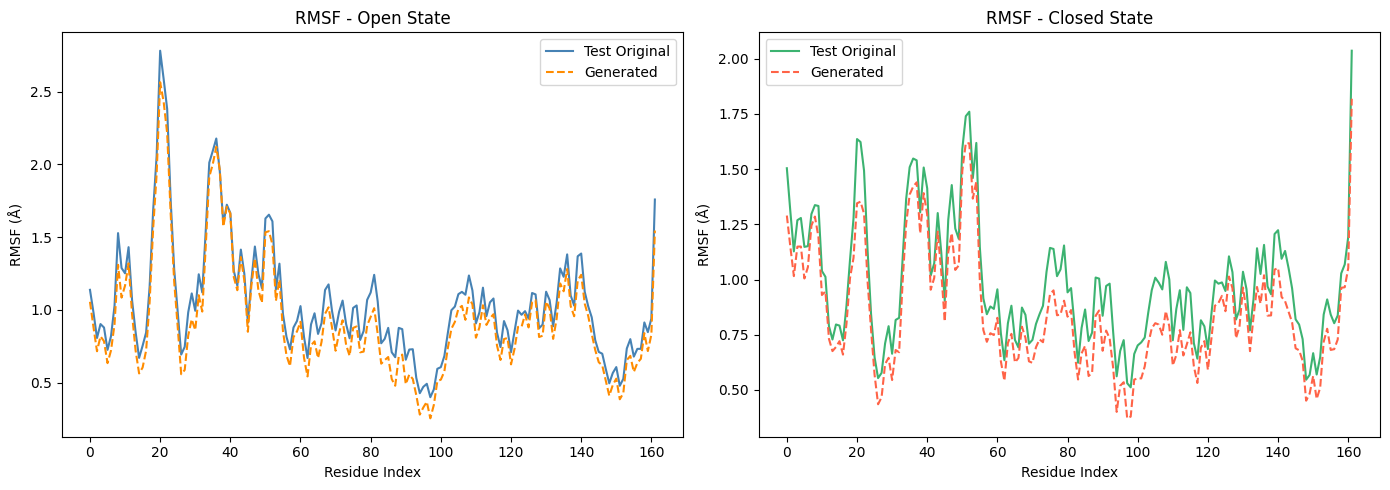

In [22]:
def calculate_rmsf(coords_array: np.ndarray) -> np.ndarray:
    mean_coords = coords_array.mean(axis=0)
    rmsf = np.sqrt(((coords_array - mean_coords)**2).sum(axis=2).mean(axis=0))
    return rmsf

rmsf_open_orig = calculate_rmsf(orig_open)
rmsf_open_gen = calculate_rmsf(gen_open_np)
rmsf_closed_orig = calculate_rmsf(orig_closed)
rmsf_closed_gen = calculate_rmsf(gen_closed_np)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(rmsf_open_orig, label='Test Original', color='steelblue')
axes[0].plot(rmsf_open_gen, label='Generated', color='darkorange', linestyle='--')
axes[0].set_title('RMSF - Open State')
axes[0].set_xlabel('Residue Index')
axes[0].set_ylabel('RMSF (Å)')
axes[0].legend()

axes[1].plot(rmsf_closed_orig, label='Test Original', color='mediumseagreen')
axes[1].plot(rmsf_closed_gen, label='Generated', color='tomato', linestyle='--')
axes[1].set_title('RMSF - Closed State')
axes[1].set_xlabel('Residue Index')
axes[1].set_ylabel('RMSF (Å)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_rmsf_se3_v2.png', dpi=150)
plt.show()

### PCA / free-energy landscape


State 0: PC1/PC2 explain 44.1% / 14.7% (train)  | PC std test [9.32 5.73]  gen [9.45 5.49]
State 1: PC1/PC2 explain 29.5% / 17.9% (train)  | PC std test [6.93 5.19]  gen [6.56 5.37]


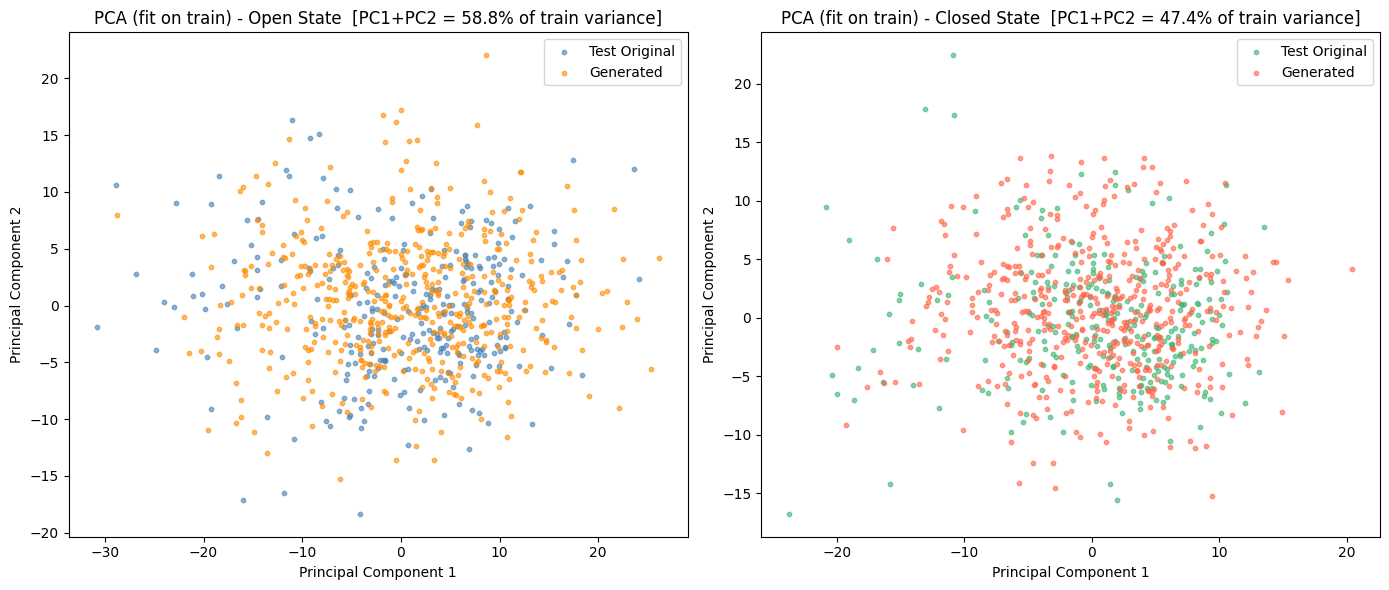

In [23]:
from sklearn.decomposition import PCA

PCA_PROJ = {}
for s, (tr, te, ge) in {0: (train_open,   orig_open,   gen_open_np),
                        1: (train_closed, orig_closed, gen_closed_np)}.items():
    pca = PCA(n_components=2).fit(tr.reshape(len(tr), -1))
    PCA_PROJ[s] = {k: pca.transform(a.reshape(len(a), -1)) for k, a in [('train', tr), ('test', te), ('gen', ge)]}
    PCA_PROJ[s]['evr'] = pca.explained_variance_ratio_
    print(f'State {s}: PC1/PC2 explain {pca.explained_variance_ratio_[0]*100:.1f}% / {pca.explained_variance_ratio_[1]*100:.1f}% (train)  | '
          f'PC std test {PCA_PROJ[s]["test"].std(0).round(2)}  gen {PCA_PROJ[s]["gen"].std(0).round(2)}')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, s, (c_t, c_g), name in zip(axes, (0, 1), [('steelblue', 'darkorange'), ('mediumseagreen', 'tomato')], ('Open', 'Closed')):
    p = PCA_PROJ[s]
    ax.scatter(p['test'][:, 0], p['test'][:, 1], alpha=0.6, label='Test Original', color=c_t, s=10)
    ax.scatter(p['gen'][:, 0],  p['gen'][:, 1],  alpha=0.6, label='Generated',     color=c_g, s=10)
    ax.set_title(f'PCA (fit on train) - {name} State  [PC1+PC2 = {p["evr"].sum()*100:.1f}% of train variance]')
    ax.set_xlabel('Principal Component 1'); ax.set_ylabel('Principal Component 2'); ax.legend()
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_pca_se3_v2.png', dpi=150)
plt.show()

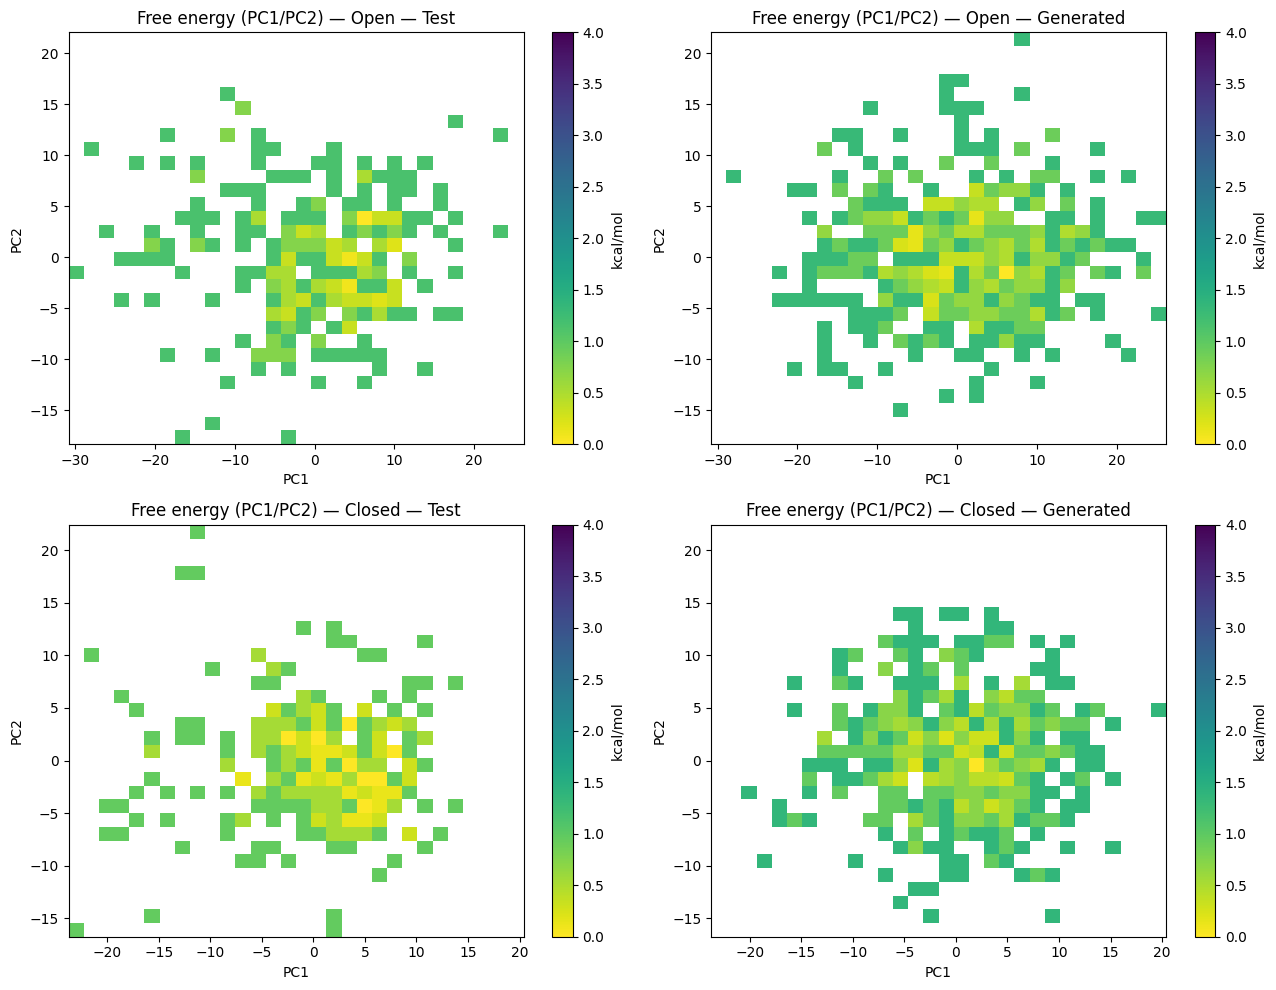

In [24]:
KT = 0.593   # kcal/mol at ~298 K

def fe_map(xy, xedges, yedges):
    H, _, _ = np.histogram2d(xy[:, 0], xy[:, 1], bins=[xedges, yedges], density=True)
    with np.errstate(divide='ignore'):
        Fm = -KT * np.log(H)                                   # FIX: a real free energy, -kT ln p
    Fm[~np.isfinite(Fm)] = np.nan
    return Fm - np.nanmin(Fm)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for r, (s, name) in enumerate([(0, 'Open'), (1, 'Closed')]):
    p = PCA_PROJ[s]
    allp = np.concatenate([p['test'], p['gen']])
    xe = np.linspace(allp[:, 0].min(), allp[:, 0].max(), 31)
    ye = np.linspace(allp[:, 1].min(), allp[:, 1].max(), 31)
    for c, (key, title) in enumerate([('test', 'Test'), ('gen', 'Generated')]):
        Fm = fe_map(p[key], xe, ye)
        im = axes[r, c].pcolormesh(xe, ye, Fm.T, cmap='viridis_r', vmin=0, vmax=4)
        axes[r, c].set_title(f'Free energy (PC1/PC2) — {name} — {title}')
        axes[r, c].set_xlabel('PC1'); axes[r, c].set_ylabel('PC2')
        plt.colorbar(im, ax=axes[r, c], label='kcal/mol')
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_free_energy_se3_v2.png', dpi=150)
plt.show()


Novelty = RMSD to nearest TRAIN structure (higher = further from the training set)...


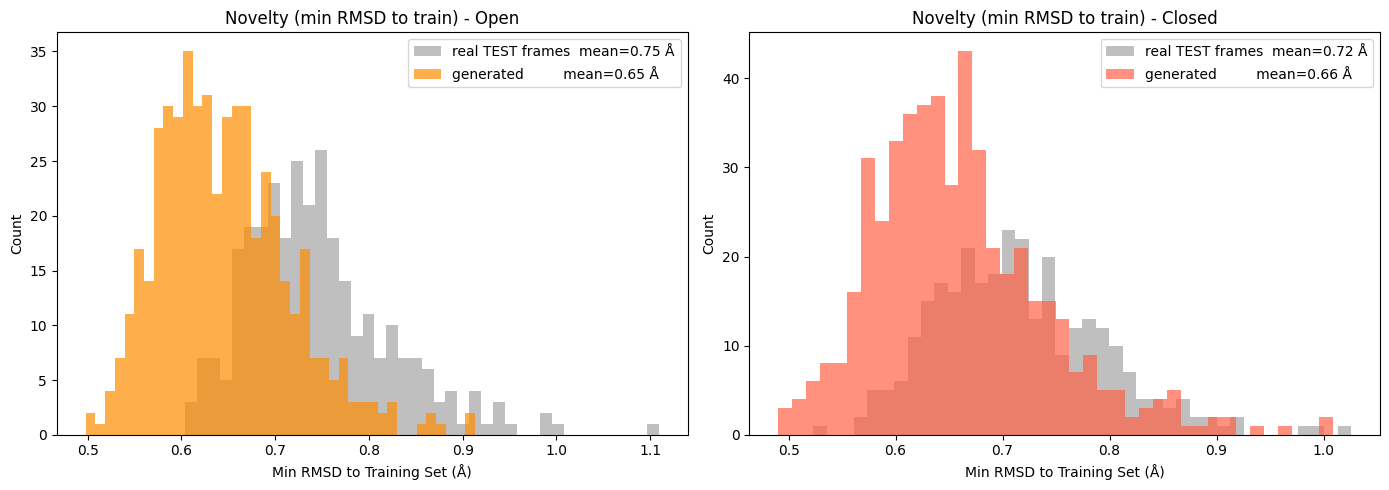

Open  : generated 0.65 Å   vs real unseen test frames 0.75 Å
Closed: generated 0.66 Å   vs real unseen test frames 0.72 Å


In [25]:
@torch.no_grad()
def nearest_rmsd_kabsch(query_np, ref_np):
    """Min Kabsch-RMSD (Å) from each query structure to ANY reference structure (batched on GPU)."""
    ref   = torch.tensor(ref_np, dtype=torch.float32, device=DEVICE)
    ref_c = ref - ref.mean(1, keepdim=True)
    out = []
    for q in torch.tensor(query_np, dtype=torch.float32, device=DEVICE):
        q_c = (q - q.mean(0)).unsqueeze(0).expand(len(ref_c), -1, -1).contiguous()
        R   = kabsch_rotation(q_c, ref_c)
        al  = torch.bmm(q_c, R)
        out.append(((al - ref_c) ** 2).sum(-1).mean(-1).sqrt().min().item())
    return np.array(out)

print('\nNovelty = RMSD to nearest TRAIN structure (higher = further from the training set)...')
nov_gen_open    = nearest_rmsd_kabsch(gen_open_np,   train_open)
nov_gen_closed  = nearest_rmsd_kabsch(gen_closed_np, train_closed)
nov_test_open   = nearest_rmsd_kabsch(orig_open,     train_open)      # reference: how "novel" are real unseen frames?
nov_test_closed = nearest_rmsd_kabsch(orig_closed,   train_closed)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (g, t, name, col) in zip(axes, [(nov_gen_open, nov_test_open, 'Open', 'darkorange'),
                                        (nov_gen_closed, nov_test_closed, 'Closed', 'tomato')]):
    ax.hist(t, bins=40, alpha=0.5, color='grey', label=f'real TEST frames  mean={t.mean():.2f} Å')
    ax.hist(g, bins=40, alpha=0.7, color=col,    label=f'generated         mean={g.mean():.2f} Å')
    ax.set_title(f'Novelty (min RMSD to train) - {name}')
    ax.set_xlabel('Min RMSD to Training Set (Å)'); ax.set_ylabel('Count'); ax.legend()
plt.tight_layout()
plt.savefig(f'{DRIVE}/eval_novelty_se3_v2.png', dpi=150)
plt.show()
print(f'Open  : generated {nov_gen_open.mean():.2f} Å   vs real unseen test frames {nov_test_open.mean():.2f} Å')
print(f'Closed: generated {nov_gen_closed.mean():.2f} Å   vs real unseen test frames {nov_test_closed.mean():.2f} Å')

### Diagnostic

In [26]:
@torch.no_grad()
def collapse_report(bs=64):
    model.eval()
    ref_t = torch.tensor(global_ref, dtype=torch.float32, device=DEVICE)
    for s in (0, 1):
        sel = np.where(labels_val == s)[0]
        xv  = torch.tensor(X_val[sel]).to(DEVICE)
        cv  = torch.tensor(coords_val[sel]).to(DEVICE)
        lv_ = torch.full((len(sel),), s, dtype=torch.long, device=DEVICE)

        mus, lvs = [], []
        for i in range(0, len(sel), bs):
            mu, lv = model.encode(xv[i:i+bs], lv_[i:i+bs]); mus.append(mu); lvs.append(lv)
        mu, lv = torch.cat(mus), torch.cat(lvs)

        def dec(z):
            return torch.cat([model.decode(z[i:i+bs], lv_[i:i+bs]) for i in range(0, len(z), bs)])

        rec_mu   = dec(mu)
        rec_rand = dec(torch.randn_like(mu))
        rec_zero = dec(torch.zeros_like(mu))
        base     = torch.tensor(coords_train[labels_train == s].mean(0), device=DEVICE).unsqueeze(0).expand_as(cv)

        r_mu   = (aligned_coord_loss(rec_mu,   cv) / RECON_SCALE).item()
        r_rand = (aligned_coord_loss(rec_rand, cv) / RECON_SCALE).item()
        r_zero = (aligned_coord_loss(rec_zero, cv) / RECON_SCALE).item()
        r_base = (aligned_coord_loss(base,     cv) / RECON_SCALE).item()

        rec_al, _ = kabsch_align_torch(ref_t, rec_mu)
        rec_std   = rec_al.std(0).mean().item()
        data_std  = cv.std(0).mean().item()
        mu_in     = mu.std(0).mean().item()
        post_std  = torch.exp(0.5 * lv).mean().item()

        print(f'State {s}  ({len(sel)} val frames)')
        print(f'  recon  z=mu: {r_mu:.4f} | z~N(0,I): {r_rand:.4f} | z=0: {r_zero:.4f} | STATE-MEAN baseline: {r_base:.4f}')
        print(f'  reconstruction spread {rec_std:.3f} Å  vs data spread {data_std:.3f} Å')
        print(f'  within-state mu std {mu_in:.3f} | mean posterior std {post_std:.3f}')
        problems = []
        if r_mu > 0.9 * r_base:   problems.append('recon is not clearly better than the state mean')
        if rec_std < 0.3 * data_std: problems.append('reconstructions have almost no spread')
        if mu_in < COLLAPSE_THR:  problems.append('mu is (almost) constant within the state')
        if abs(r_rand - r_mu) < 0.02 * max(r_mu, 1e-6): problems.append('decoder output does not depend on z')
        print('  VERDICT:', 'OK - latent is used' if not problems else 'COLLAPSED -> ' + '; '.join(problems))
        d = coords_train[labels_train == s].reshape(-1, N_CA * 3)
        evr = PCA(10).fit(d).explained_variance_ratio_
        print(f'  (data within-state PCA: top-1 {evr[0]:.2f}, top-5 {evr[:5].sum():.2f}, top-10 {evr.sum():.2f})\n')

collapse_report()

State 0  (300 val frames)
  recon  z=mu: 0.3615 | z~N(0,I): 3.5429 | z=0: 2.5081 | STATE-MEAN baseline: 1.9232
  reconstruction spread 0.533 Å  vs data spread 0.609 Å
  within-state mu std 0.566 | mean posterior std 0.064
  VERDICT: OK - latent is used
  (data within-state PCA: top-1 0.44, top-5 0.72, top-10 0.79)

State 1  (300 val frames)
  recon  z=mu: 0.3713 | z~N(0,I): 3.0490 | z=0: 1.7155 | STATE-MEAN baseline: 1.6063
  reconstruction spread 0.478 Å  vs data spread 0.562 Å
  within-state mu std 0.508 | mean posterior std 0.057
  VERDICT: OK - latent is used
  (data within-state PCA: top-1 0.30, top-5 0.66, top-10 0.75)

